# Conect to google drive

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


# Libraries

## External

In [ ]:
!pip install -q wfdb einops
print("done!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.0/160.0 kB 3.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 4.9 MB/s eta 0:00:00
done!


In [ ]:
import os
import wfdb
from matplotlib import pyplot as plt
from tqdm import tqdm
import tensorflow as tf
import seaborn as sns
import keras
from keras import layers

%matplotlib inline
sns.set_theme()

## Internal

In [ ]:
import sys
sys.path.append('/content/gdrive/MyDrive/Doutorado/emg_estimator')

In [ ]:
from utils.utils import *
from dataloader.dataloader import *
# from models.estimator import estimator
from models.data_augmentation import *
from models.oselm import OS_ELM

## Create paths

In [ ]:
sys.path.append('/content/gdrive')

In [ ]:
path = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject01_session1"
dir_list = os.listdir(path)

path2 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject01_session2"
dir_list2 = os.listdir(path2)

## Create the datasets

### Training dataset

In [ ]:
emg_files_train_finger1 = [
    "1dof_preprocess_finger1_sample1.hea",
    "1dof_preprocess_finger1_sample2.hea",
]
emg_files_train_finger2 = [
    "1dof_preprocess_finger2_sample1.hea",
    "1dof_preprocess_finger2_sample2.hea",
]
emg_files_train_finger3 = [
    "1dof_preprocess_finger3_sample1.hea",
    "1dof_preprocess_finger3_sample2.hea",
]
emg_files_train_finger4 = [
    "1dof_preprocess_finger4_sample1.hea",
    "1dof_preprocess_finger4_sample2.hea",
]
emg_files_train_finger5 = [
    "1dof_preprocess_finger5_sample1.hea",
    "1dof_preprocess_finger5_sample2.hea",
]

force_files_train_finger1 = [
    "1dof_force_finger1_sample1.hea",
    "1dof_force_finger1_sample2.hea",
]
force_files_train_finger2 = [
    "1dof_force_finger2_sample1.hea",
    "1dof_force_finger2_sample2.hea",
]
force_files_train_finger3 = [
    "1dof_force_finger3_sample1.hea",
    "1dof_force_finger3_sample2.hea",
]
force_files_train_finger4 = [
    "1dof_force_finger4_sample1.hea",
    "1dof_force_finger4_sample2.hea",
]
force_files_train_finger5 = [
    "1dof_force_finger5_sample1.hea",
    "1dof_force_finger5_sample2.hea",
]

In [ ]:
train_dataset_f1 = create_synced_datasets(
    path, emg_files_train_finger1, force_files_train_finger1
) # train_weights
train_dataset_f2 = create_synced_datasets(
    path, emg_files_train_finger2, force_files_train_finger2
)
train_dataset_f3 = create_synced_datasets(
    path, emg_files_train_finger3, force_files_train_finger3
)
train_dataset_f4 = create_synced_datasets(
    path, emg_files_train_finger4, force_files_train_finger4
)
train_dataset_f5 = create_synced_datasets(
    path, emg_files_train_finger5, force_files_train_finger5
)

### Validation dataset

In [ ]:
emg_files_val_finger1 = [
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_val_finger2 = [
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_val_finger3 = [
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_val_finger4 = [
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_val_finger5 = [
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_val_finger1 = [
    "1dof_force_finger1_sample3.hea",
]
force_files_val_finger2 = [
    "1dof_force_finger2_sample3.hea",
]
force_files_val_finger3 = [
    "1dof_force_finger3_sample3.hea",
]
force_files_val_finger4 = [
    "1dof_force_finger4_sample3.hea",
]
force_files_val_finger5 = [
    "1dof_force_finger5_sample3.hea",
]

In [ ]:
val_dataset_f1 = create_synced_datasets(
    path, emg_files_val_finger1, force_files_val_finger1
) # val_weights
val_dataset_f2 = create_synced_datasets(
    path, emg_files_val_finger2, force_files_val_finger2
)
val_dataset_f3 = create_synced_datasets(
    path, emg_files_val_finger3, force_files_val_finger3
)
val_dataset_f4 = create_synced_datasets(
    path, emg_files_val_finger4, force_files_val_finger4
)
val_dataset_f5 = create_synced_datasets(
    path, emg_files_val_finger5, force_files_val_finger5
)

In [ ]:
emg_files_test_finger1 = [
    # "1dof_preprocess_finger1_sample1.hea",
    # "1dof_preprocess_finger1_sample2.hea",
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_test_finger2 = [
    # "1dof_preprocess_finger2_sample1.hea",
    # "1dof_preprocess_finger2_sample2.hea",
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_test_finger3 = [
    # "1dof_preprocess_finger3_sample1.hea",
    # "1dof_preprocess_finger3_sample2.hea",
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_test_finger4 = [
    # "1dof_preprocess_finger4_sample1.hea",
    # "1dof_preprocess_finger4_sample2.hea",
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_test_finger5 = [
    # "1dof_preprocess_finger5_sample1.hea",
    # "1dof_preprocess_finger5_sample2.hea",
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_test_finger1 = [
    # "1dof_force_finger1_sample1.hea",
    # "1dof_force_finger1_sample2.hea",
    "1dof_force_finger1_sample3.hea",
]
force_files_test_finger2 = [
    # "1dof_force_finger2_sample1.hea",
    # "1dof_force_finger2_sample2.hea",
    "1dof_force_finger2_sample3.hea",
]
force_files_test_finger3 = [
    # "1dof_force_finger3_sample1.hea",
    # "1dof_force_finger3_sample2.hea",
    "1dof_force_finger3_sample3.hea",
]
force_files_test_finger4 = [
    # "1dof_force_finger4_sample1.hea",
    # "1dof_force_finger4_sample2.hea",
    "1dof_force_finger4_sample3.hea",
]
force_files_test_finger5 = [
    "1dof_force_finger5_sample1.hea",
    # "1dof_force_finger5_sample2.hea",
    "1dof_force_finger5_sample3.hea",
]

In [ ]:
test_dataset_f1 = create_synced_datasets(
    path2, emg_files_test_finger1, force_files_test_finger1
)
test_dataset_f2 = create_synced_datasets(
    path2, emg_files_test_finger2, force_files_test_finger2
)
test_dataset_f3 = create_synced_datasets(
    path2, emg_files_test_finger3, force_files_test_finger3
)
test_dataset_f4 = create_synced_datasets(
    path2, emg_files_test_finger4, force_files_test_finger4
)
test_dataset_f5 = create_synced_datasets(
    path2, emg_files_test_finger5, force_files_test_finger5
)

# Create the base model

In [ ]:
import tensorflow as tf
import einops
import keras
from keras import layers

class ResidualMain(keras.layers.Layer):
  """
    Residual block of the model with convolution, layer normalization, and
    the activation function, ReLU.
  """
  def __init__(self, filters, kernel_size):
    super().__init__()
    self.seq = keras.Sequential([
        Conv2Plus1D(filters=filters,
                    kernel_size=kernel_size,
                    padding='same'),
        layers.LayerNormalization(),
        layers.ReLU(),
        Conv2Plus1D(filters=filters,
                    kernel_size=kernel_size,
                    padding='same'),
        layers.LayerNormalization()
    ])

  def call(self, x):
    # x = tf.expand_dims(x, -2)  # Add a new channel axis
    return self.seq(x)


class Project(keras.layers.Layer):
  """
    Project certain dimensions of the tensor as the data is passed through
    different sized filters and downsampled.
  """
  def __init__(self, units):
    super().__init__()
    self.seq = keras.Sequential([
        layers.Dense(units),
        layers.LayerNormalization()
    ])

  def call(self, x):
    return self.seq(x)


def add_residual_block(input, filters, kernel_size):
  """
    Add residual blocks to the model. If the last dimensions of the input
    data and filter size does not match, project it such that last
    dimension matches.
  """
  out = ResidualMain(filters,
                     kernel_size)(input)

  res = input
  # Using the Keras functional APIs, project the last dimension of the
  # tensor to match the new filter size
  if out.shape[-1] != input.shape[-1]:
    res = Project(out.shape[-1])(res)

  return layers.add([res, out])


class ResizeSignal(keras.layers.Layer):
  def __init__(self, height, width):
    super().__init__()
    self.height = height
    self.width = width
    self.resizing_layer = layers.Resizing(self.height, self.width)

  def call(self, signal):
    """
      Use the einops library to resize the tensor.

      Args:
        Signal: Tensor representation of the signal, in the form of a set
        of frames.

      Return:
        A downsampled size of the signal according to the new height and
        width it should be resized to.
    """
    # b stands for batch size, t stands for time, h stands for height,
    # w stands for width, and c stands for the number of channels.
    old_shape = einops.parse_shape(signal, 'b t h w c')
    images = einops.rearrange(signal, 'b t h w c -> (b t) h w c')
    images = self.resizing_layer(images)
    signals = einops.rearrange(
        images, '(b t) h w c -> b t h w c',
        t = old_shape['t'])
    return signals

class Conv2Plus1D(keras.layers.Layer):
    def __init__(
        self,
        filters,
        kernel_size,
        padding,
        activation='linear',
        dilation_rate=1,
        **kwargs
        ):
        """
          A sequence of convolutional layers that first apply the convolution
          operation over the spatial dimensions, and then the temporal
          dimension.
        """
        super().__init__(**kwargs)
        self.spatial_conv = layers.Conv3D(
            filters=filters,
            kernel_size=(1, kernel_size[1], kernel_size[2]),
            padding=padding,
            activation=activation,
            dilation_rate=(1, dilation_rate, dilation_rate)
            )
        self.temporal_conv = layers.Conv3D(
            filters=filters,
            kernel_size=(kernel_size[0], 1, 1),
            padding=padding,
            activation=activation,
            dilation_rate=(dilation_rate, 1, 1)
            )
        self.batch_norm = layers.BatchNormalization()

    def call(self, x):
        x = self.spatial_conv(x)
        x = self.temporal_conv(x)
        x = self.batch_norm(x)
        x = tf.keras.activations.relu(x)
        return x

class DilatedConv2Plus1D(tf.keras.layers.Layer):
    """
    The dilation rate is set as an attribute and determines the spacing
     between the kernel elements during convolution, allowing for an
     increased receptive field.
    """
    def __init__(self, dilation_rate, filters, kernel_size, **kwargs):
        super().__init__(**kwargs)
        self.conv2plus1d = Conv2Plus1D(
            filters=filters, kernel_size=kernel_size, padding="same"
            )
        self.batchnorm = tf.keras.layers.BatchNormalization()
        self.dilation_rate = dilation_rate  # save dilation_rate as an attribute

    def call(self, x):
        x = self.conv2plus1d(x)
        x = self.batchnorm(x)
        x = tf.keras.activations.relu(x)
        return x


class Estimator(tf.keras.Model):
    """
    The WaveNet class is a neural network model that uses the
    DilatedConv2Plus1D class to build WaveNet blocks with a variable number
    of layers and dilations
    """

    def __init__(self, num_blocks, num_layers, filters, kernel_size, dilations, input_shape_, **kwargs):
        super(Estimator, self).__init__(**kwargs)
        self.num_blocks = num_blocks
        self.num_layers = num_layers
        self.filters = filters
        self.kernel_size = kernel_size
        self.dilations = dilations
        self.input_shape_ = input_shape_

        # Build the model
        self.build_model()

    def build_model(self):
        # Define input layer
        inputs = tf.keras.Input(shape=self.input_shape_)

        # Build WaveNet blocks
        x = inputs
        for i in range(self.num_blocks):
            for j in range(self.num_layers):
                dilation_rate = self.dilations[j % len(self.dilations)]
                x = DilatedConv2Plus1D(dilation_rate=dilation_rate, filters=self.filters, kernel_size=self.kernel_size)(x)
        x = tf.keras.layers.ELU()(x)

        # Add residual blocks
        for i in range(self.num_blocks):
            x = add_residual_block(x, self.filters, (18, 3, 3))
            x = ResizeSignal(-(-x.shape[2] // (2*(i+1))), -(-x.shape[3] // (2*(i+1))))(x)
        x = tf.keras.layers.GlobalAveragePooling3D()(x)
        x = tf.keras.layers.Flatten()(x)
        outputs = layers.ReLU()(x)

        # Output layer
        # outputs = tf.keras.layers.Dense(1, activation="linear")(x)

        # Create the model
        self.model = tf.keras.Model(inputs=inputs, outputs=outputs)

    def call(self, inputs):
        return self.model(inputs)

    def summary(self):
        self.model.summary()

    def plot_model(self, show_shapes=False):
        tf.keras.utils.plot_model(
            self.model,
            show_shapes=show_shapes
        )



def estimator(
    num_blocks,
    num_layers,
    filters,
    kernel_size,
    dilations,
    input_shape_,
    # num_lstm_blocks,
    ):
    """
    The WaveNet function is a neural network model that uses the
    DilatedConv2Plus1D class to build WaveNet blocks with a variable number
    of layers and dilations
    """
    # Define input layer
    input_layer = layers.Input(shape=input_shape_)

    # Build WaveNet blocks
    x = input_layer
    for i in range(num_blocks):
        for j in range(num_layers):
            dilation_rate = dilations[j % len(dilations)]
            x = DilatedConv2Plus1D(
                dilation_rate=dilation_rate,
                filters=filters,
                kernel_size=kernel_size
            )(x)
    x = layers.ELU()(x)
    # Add residual blocks
    for i in range(num_blocks):
        x = add_residual_block(x, filters*(i+1), (18, 3, 3))
        x = ResizeSignal(x.shape[2] // 2*(i+1), x.shape[3] // 2*(i+1))(x)
    x = layers.GlobalAveragePooling3D()(x)
    x = layers.Flatten()(x)
    x = layers.ReLU()(x)
    # Linear combinator layer
    # x = layers.Dense(1, activation="linear")(x)
    # Create the Keras model
    model = tf.keras.Model(inputs=input_layer, outputs=x)

    return model

In [ ]:
kernel_size=(18, 3, 3)
dilations=[1, 2, 4]
input_shape = [100, 16, 16, 1] # train_dataset.element_spec[0].shape

estimator_f4 = Estimator(
    num_blocks=3, num_layers=3, filters=16,
    kernel_size=kernel_size, dilations=dilations,
    input_shape_=input_shape,
)

estimator_f4.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 100, 16, 16  0           []                               
                                , 1)]                                                             
                                                                                                  
 dilated_conv2_plus1d (DilatedC  (None, 100, 16, 16,  4912       ['input_1[0][0]']                
 onv2Plus1D)                     16)                                                              
                                                                                                  
 dilated_conv2_plus1d_1 (Dilate  (None, 100, 16, 16,  7072       ['dilated_conv2_plus1d[0][0]']   
 dConv2Plus1D)                   16)                                                          

In [ ]:
from tensorflow.keras.layers import Layer
from tensorflow.keras import backend as K


class OSELM:
    def __init__(self, input_size, output_size, hidden_layer_size, random_state=None):
        self.input_size = input_size
        self.output_size = output_size
        self.hidden_layer_size = hidden_layer_size
        self.input_weights = tf.Variable(tf.random.uniform(shape=[input_size, hidden_layer_size], minval=-1, maxval=1))
        self.bias = tf.Variable(tf.random.uniform(shape=[hidden_layer_size], minval=-1, maxval=1))
        self.output_weights = tf.Variable(tf.random.uniform(shape=[hidden_layer_size + 1, output_size], minval=-1, maxval=1))
        self.random_state = random_state
        self.H = None
        self.beta = None

    def relu(self, x):
        return tf.maximum(0, x)

    def fit(self, X, y, regularization=0, batch_size=None):
        if self.random_state is not None:
            tf.random.set_seed(self.random_state)

        X = tf.convert_to_tensor(X, dtype=tf.float32)
        y = tf.convert_to_tensor(y, dtype=tf.float32)

        if batch_size is None:
            H = self.relu(tf.matmul(X, self.input_weights) + self.bias)
            H = tf.concat([H, tf.ones((tf.shape(H)[0], 1))], axis=-1)  # add bias term
            self.beta = tf.linalg.pinv(tf.matmul(tf.transpose(H), H) + regularization * tf.eye(H.shape[1])) @ tf.matmul(tf.transpose(H), y)
        else:
            n_samples = X.shape[0]
            n_batches = int(tf.math.ceil(n_samples / batch_size))
            H_batches = []
            y_batches = []
            for i in range(n_batches):
                start = i * batch_size
                end = min((i + 1) * batch_size, n_samples)
                H_batch = self.relu(tf.matmul(X[start:end], self.input_weights) + self.bias)
                H_batch = tf.concat([H_batch, tf.ones((tf.shape(H_batch)[0], 1))], axis=-1)  # add bias term
                H_batches.append(H_batch)
                y_batches.append(y[start:end])
            H = tf.concat(H_batches, axis=0)
            y = tf.concat(y_batches, axis=0)
            self.beta = tf.linalg.pinv(tf.matmul(tf.transpose(H), H) + regularization * tf.eye(H.shape[1])) @ tf.matmul(tf.transpose(H), y)

        self.H = H

    def predict(self, X):
        X = tf.convert_to_tensor(X, dtype=tf.float32)
        H = self.relu(tf.matmul(X, self.input_weights) + self.bias)
        H = tf.concat([H, tf.ones((tf.shape(H)[0], 1))], axis=-1)  # add bias term
        y_pred = tf.matmul(H, self.beta)
        return y_pred


# class OSELM(tf.keras.Model):
#
#     def __init__(self, input_size, output_size, hidden_layer_size):
#         super(OSELM, self).__init__()
#
#         self.dropout = layers.Dropout(0.4)
#         self.hidden_layer = layers.Dense(hidden_layer_size, activation='relu')
#         self.output_layer = layers.Dense(output_size, activation='linear')
#
#     # @tf.function(jit_compile=True)
#     def call(self, inputs):
#         d = self.dropout(inputs)
#         h = self.hidden_layer(d)
#         o = self.output_layer(h)
#         return o

In [ ]:
# features_extractor = keras.Model(estimator_f4.inputs, estimator_f4.layers[-2].output)

In [ ]:
# Define o modelo completo
oselm = OSELM(input_size=16, output_size=5, hidden_layer_size=128)

# features_extractor = keras.Model(estimator_f4.inputs, estimator_f4.layers[-2].output)

inputs = tf.keras.layers.Input(shape=(100, 16, 16, 1))

latent = estimator_f4(inputs) # features_extractor(inputs)

outputs = oselm(latent)

new_estimator_f4 = tf.keras.Model(inputs,  outputs)

In [ ]:
new_estimator_f4.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 100, 16, 16, 1)]  0         
                                                                 
 estimator (Estimator)       (None, 16)                103728    
                                                                 
 oselm (OSELM)               (None, 5)                 2821      
                                                                 
Total params: 106,549
Trainable params: 105,781
Non-trainable params: 768
_________________________________________________________________


## Model Training

### Callbacks

In [ ]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/oselm_estimator_4/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        save_format="tf.saved_model"
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/oselm_estimator_4/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.EarlyStopping(
      patience=20,
      restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=5,
        min_lr=1e-8,
    ),
]

In [ ]:
batch_size = 8

dataset_train_f4 = train_dataset_f4.shuffle(buffer_size=len(train_dataset_f4)).batch(batch_size)
dataset_val_f4 = val_dataset_f4.batch(batch_size)

# Data augumentation

In [ ]:
import tensorflow as tf
import numpy as np
from scipy.signal import butter, lfilter

class ButterworthFilterLayer(tf.keras.layers.Layer):
    def __init__(self, lowcut, highcut, fs, btype='band', order=4, seed=42, **kwargs):
        super(ButterworthFilterLayer, self).__init__(**kwargs)
        self.lowcut = lowcut
        self.highcut = highcut
        self.fs = fs
        self.btype = btype
        self.order = order
        self.seed = seed

        # Definir a semente (seed) para reprodutibilidade
        tf.random.set_seed(seed)
        np.random.seed(seed)

        # Gerar aleatoriamente os valores de lowcut e highcut dentro dos limites especificados
        lowcut_freq = np.random.uniform(0, 1) * lowcut
        highcut_freq = np.random.uniform(highcut / fs, 0.5) * fs

        # Criar os coeficientes do filtro Butterworth usando SciPy
        nyquist = 0.5 * fs
        lowcut_normal = lowcut_freq / nyquist
        highcut_normal = highcut_freq / nyquist
        b, a = butter(order, [lowcut_normal, highcut_normal], btype=btype, analog=False)

        # Convert the filter coefficients to tf.float32 data type
        self.b = tf.convert_to_tensor(b, dtype=tf.float32)
        self.a = tf.convert_to_tensor(a, dtype=tf.float32)

    # @tf.function(jit_compile=True)
    def call(self, inputs, training=False):
        if training:
            # Obter as dimensões do tensor de entrada
            batch_size, num_windows, height, width, channels = inputs.shape

            # Aplainar o tensor de entrada para que cada janela seja tratada individualmente
            inputs = tf.cast(inputs, tf.float32)
            inputs_flattened = tf.reshape(inputs, [-1, height, width, channels])

            # Converter o tensor achatado para numpy array e aplicar o filtro Butterworth
            filtered_signal_flattened = tf.numpy_function(lfilter, [self.b, self.a, inputs_flattened], tf.float32)
            print(filtered_signal_flattened)

            # Redefinir as dimensões do tensor para a forma original (batch_size, num_windows, height, width, channels)
            filtered_signal = tf.reshape(filtered_signal_flattened, [batch_size, num_windows, height, width, channels])
            return filtered_signal
        return inputs


class FrequencyClippingLayer(tf.keras.layers.Layer):
    def __init__(self, lowcut=5.0, highcut=50.0, seed=None, **kwargs):
        super(FrequencyClippingLayer, self).__init__(**kwargs)
        self.lowcut = lowcut
        self.highcut = highcut
        self.seed = seed

    def call(self, inputs, training=False):
        if training:
            # Obter o shape do tensor de entrada
            input_shape = tf.shape(inputs)
            # Definir a semente para a geração de números aleatórios
            if self.seed is not None:
                tf.random.set_seed(self.seed)
            # Realizar a transformada rápida de Fourier
            fft_signal = tf.signal.fft(tf.complex(inputs, 0.0))
            # Gerar valores aleatórios de clip_low e clip_high dentro dos intervalos desejados
            lowcut = tf.random.uniform(shape=[], minval=0.0, maxval=self.lowcut, dtype=tf.float32)
            highcut = tf.random.uniform(shape=[], minval=self.highcut, maxval=600.0, dtype=tf.float32)
            # Recortar as frequências abaixo de lowcut
            fft_signal_real = tf.cast(tf.math.real(fft_signal), dtype=tf.float32)
            fft_signal = tf.where(tf.abs(fft_signal_real) < lowcut, 0.0, fft_signal_real, name="clip_low_mask")
            # Recortar as frequências acima de highcut
            fft_signal = tf.where(tf.abs(fft_signal) > highcut, 0.0, fft_signal, name="clip_high_mask")
            # Realizar a transformada inversa de Fourier
            clipped_signal = tf.signal.ifft(tf.complex(fft_signal, 0.0))
            return tf.cast(tf.math.real(clipped_signal), dtype=tf.float32)
        return inputs

# Exemplo de uso da camada personalizada
batch_size = 32
num_windows = 100
height = 16
width = 16
channels = 1

sampling_rate = 2048.0   # Taxa de amostragem (ajuste conforme necessário)
filter_order = 4        # Ordem do filtro (ajuste conforme necessário)

# Criar um sinal de exemplo (batch_size, number_of_windows, height, width, channels)
signal = tf.random.normal((batch_size, num_windows, height, width, channels))

# Criar o modelo com a camada personalizada
model = tf.keras.Sequential([
    FrequencyClippingLayer(lowcut=100, highcut=400)
])

# Compilar o modelo e visualizar a arquitetura
model.compile(optimizer='adam', loss='mse')

# Testar o modelo com o sinal de exemplo
output_signal = model.predict(signal)
print("Output signal shape:", output_signal.shape)

1/1 [==============================] - 0s 222ms/step
Output signal shape: (32, 100, 16, 16, 1)


In [ ]:
pi = tf.constant(3.141592653589793)

#Variância do sinal de emg
variances = []
for emg, force in train_dataset_f4:
    var = tf.math.reduce_variance(emg)
    variances.append(var)
mean_variance = tf.reduce_mean(variances)
var = 0.1 * mean_variance
# desvio padrão do ruído gaussiano
std = tf.math.sqrt(var)

data_augmentation = tf.keras.Sequential([
    layers.GaussianNoise(stddev=std),
    AmplitudeScalingLayer(scale_range=(0.8, 1.2)),
    TimeShiftLayer(max_shift=0.2),
    PhaseRotationLayer(rotation_range=(-pi/7, pi/7)),
    TimeMasking3D(0.2),
    FrequencyClippingLayer(lowcut=20, highcut=550),
    layers.Dropout(0.2),
])

model = tf.keras.Sequential([
    # data_augmentation,
    new_estimator_f4,
])

# Training

In [ ]:
# Compilar o modelo
optimizer = keras.optimizers.Adam(learning_rate=1e-3)
model.compile(optimizer=optimizer, loss='mse')
# Fit data to model

history = model.fit(
    dataset_train_f4,
    epochs=100,
    validation_data=dataset_val_f4,
    callbacks=callback,
)

Epoch 1/100
599/599 [==============================] - ETA: 0s - loss: 0.0241
Epoch 1: val_loss improved from inf to 0.03429, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/oselm_estimator_4/
599/599 [==============================] - 167s 257ms/step - loss: 0.0241 - val_loss: 0.0343 - lr: 0.0010
Epoch 2/100
599/599 [==============================] - ETA: 0s - loss: 0.0088
Epoch 2: val_loss improved from 0.03429 to 0.02929, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/oselm_estimator_4/
599/599 [==============================] - 152s 254ms/step - loss: 0.0088 - val_loss: 0.0293 - lr: 0.0010
Epoch 3/100
599/599 [==============================] - ETA: 0s - loss: 0.0057
Epoch 3: val_loss improved from 0.02929 to 0.01393, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/oselm_estimator_4/
599/599 [==============================] - 152s 254ms/step - loss: 0.0057 - val_loss: 0.0139 - lr: 

In [ ]:
# for epoch in range(num_epochs):
#     for batch_x, batch_y in dataset_train_f1:
#         loss = model.train_on_batch(batch_x, batch_y)

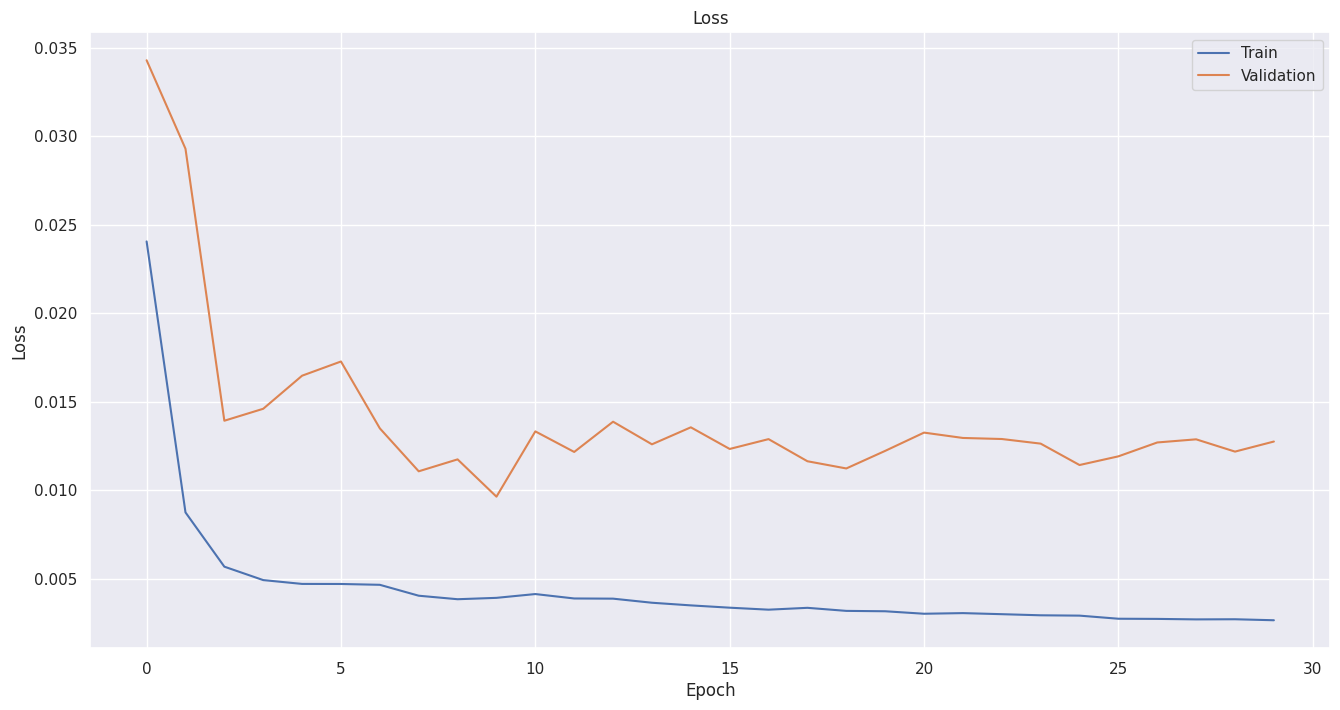

In [ ]:
# Plot training & validation loss values
fig, ax = plt.subplots(figsize=(16, 8))
ax.set_title('Loss')
ax.plot(history.history['loss'], label = 'train')
ax.plot(history.history['val_loss'], label = 'test')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Validation'])

## Testing

In [ ]:
emg_signal_windows_test, force_signal_test = [], []
for emg, f in test_dataset_f4:
    emg_signal_windows_test.append(emg)
    force_signal_test.append(f)
emg_signal_windows_test = tf.constant(
    np.array(emg_signal_windows_test)
)
force_signal_test = tf.constant(
    np.array(force_signal_test)
)

print(emg_signal_windows_test.shape)
print(force_signal_test.shape)

(2395, 100, 16, 16, 1)
(2395, 5)


In [ ]:
predicted_test = new_estimator_f4.predict(emg_signal_windows_test)

75/75 [==============================] - 19s 237ms/step


In [ ]:
errors_f4 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f4)}')
print(f'variance error: {tf.math.reduce_variance(errors_f4)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

mean error: 0.02118716947734356
variance error: 9.280051745008677e-05
r^2: -5.573733544680444


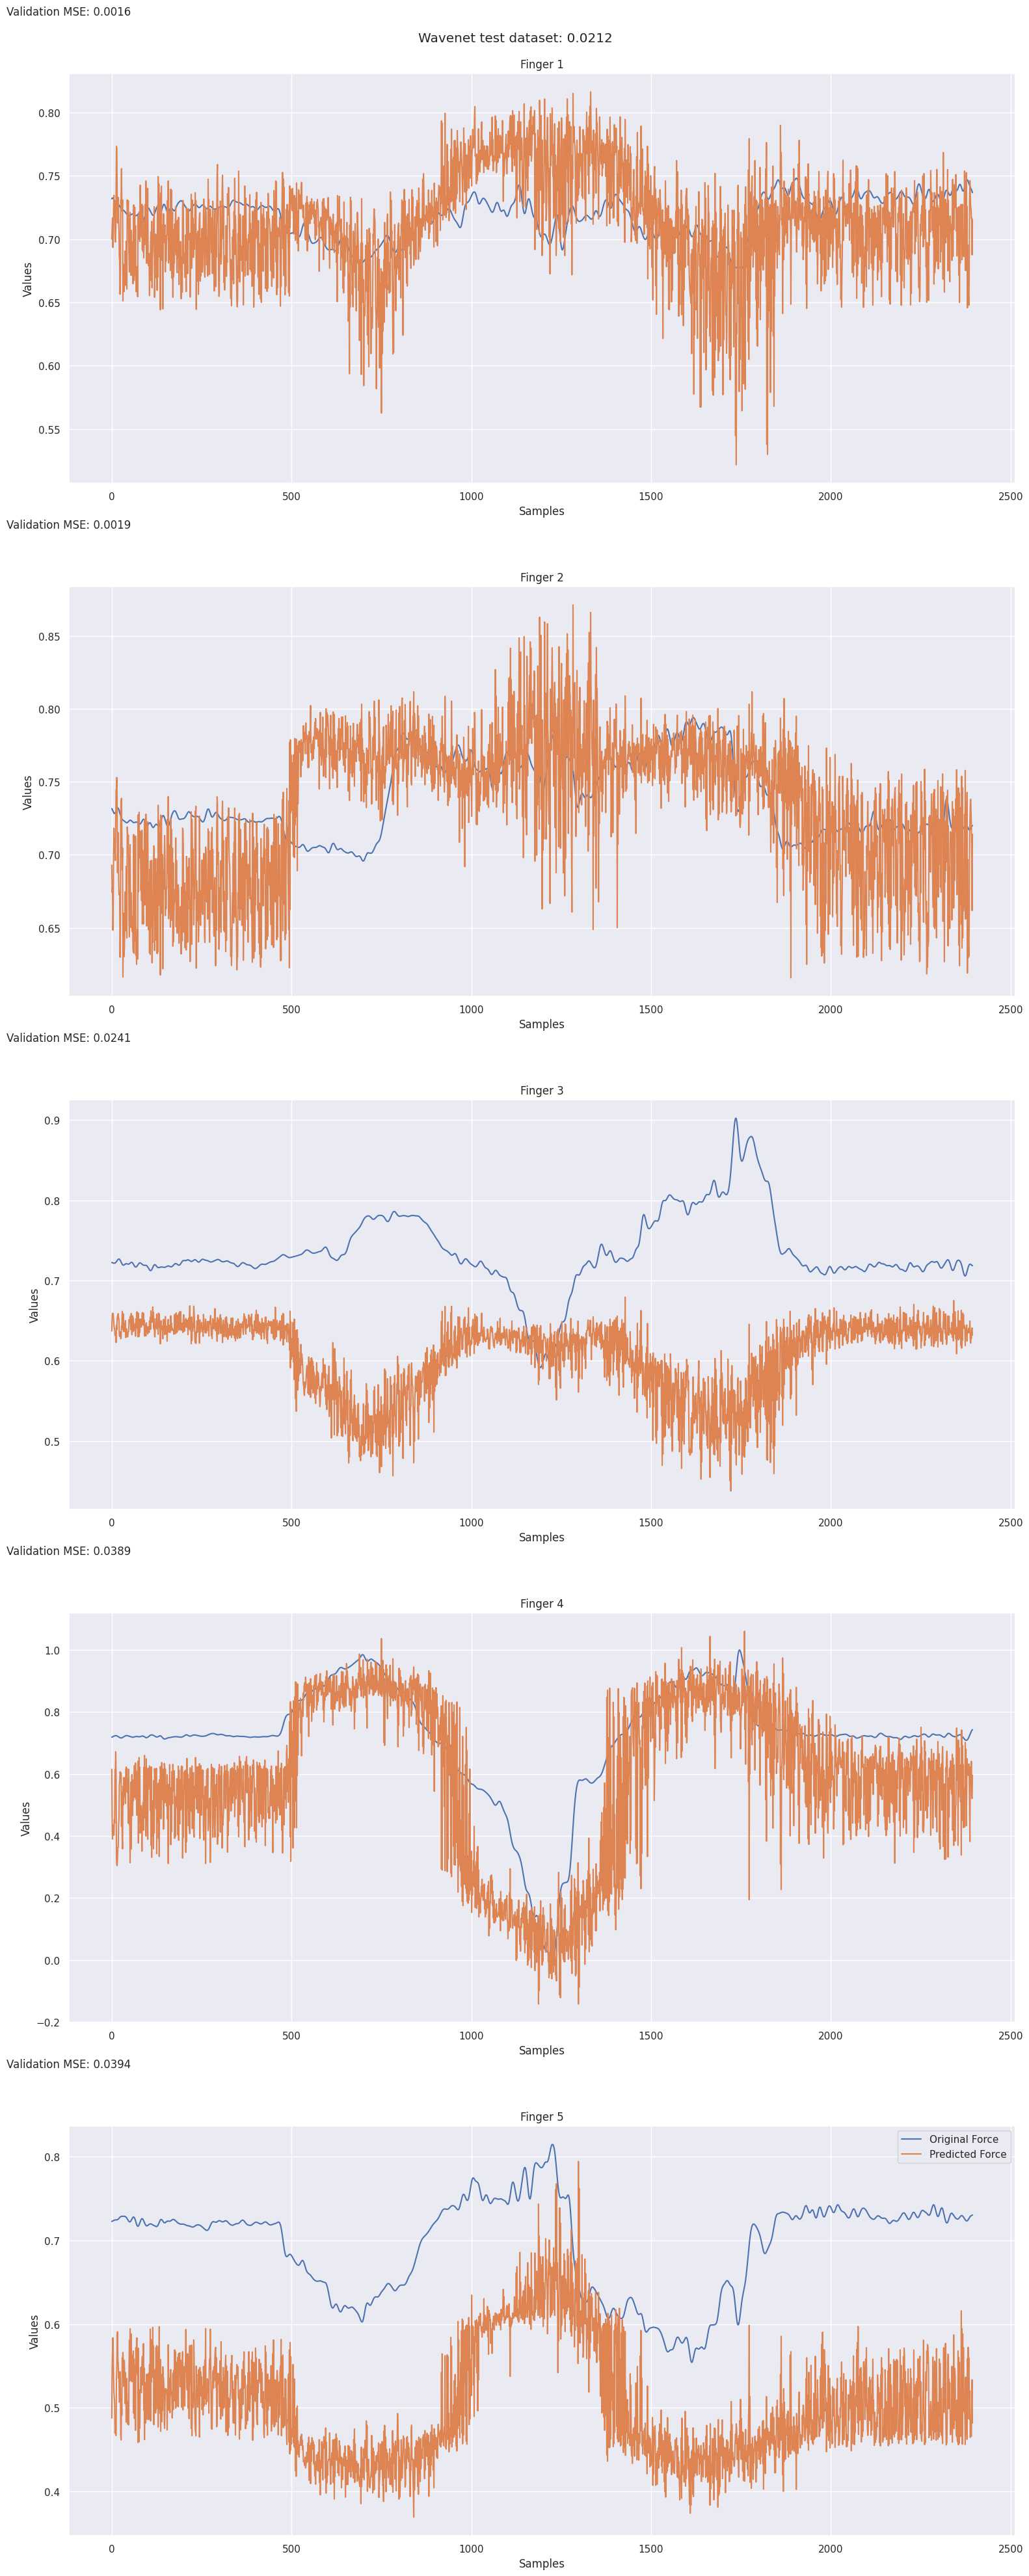

In [ ]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)

# Create subplots in a 5x1 grid
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(16, 40))

mse_ = calc_mse(predicted_test, outputs)
title = f"Wavenet test dataset: {mse_:.4f}"

for i, ax in enumerate(axes):
    mse = calc_mse(predicted_test[:, i], outputs[:, i])  # Calculate MSE for each finger separately
    ax.plot(outputs[:, i], label='Original Force')
    ax.plot(predicted_test[:, i], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
            ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {i+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")

plt.suptitle(title)
plt.tight_layout()
plt.legend()
plt.show()

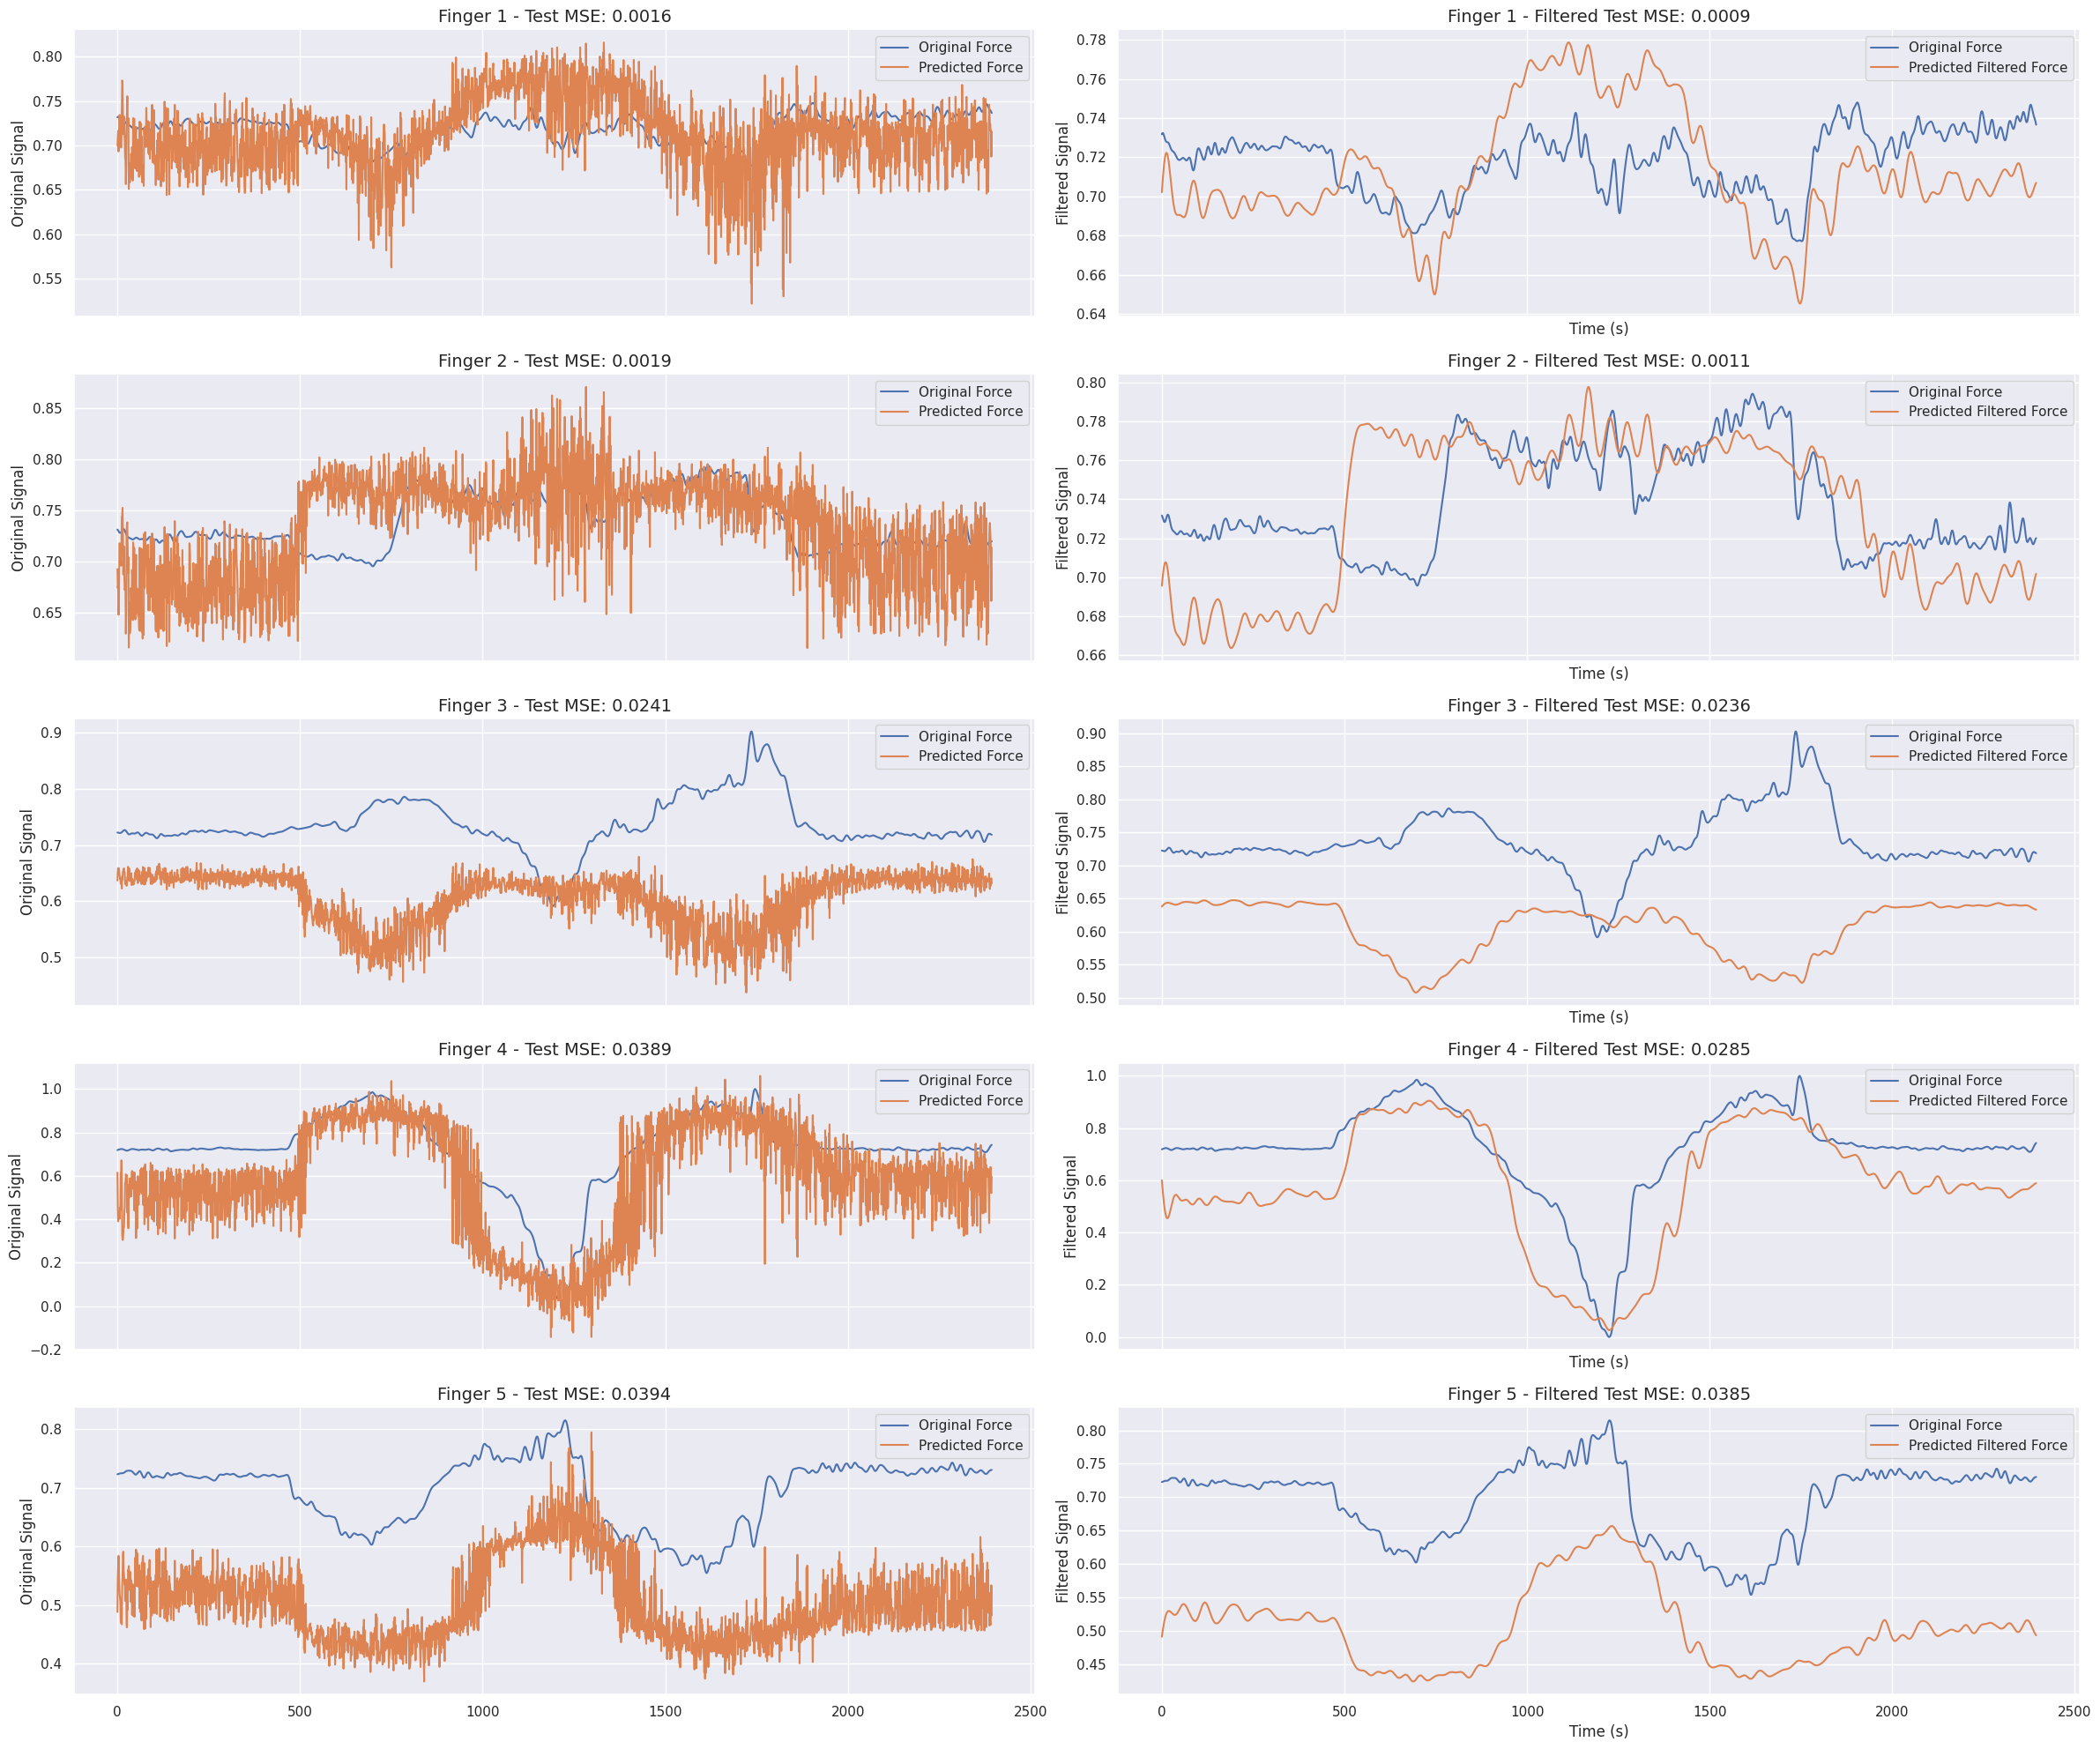

In [ ]:
from scipy.signal import butter, filtfilt, iirnotch

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

plt.tight_layout()
plt.show()

In [ ]:
for i in range(5):
    print(f'Finger {i+1} - r^2: {r2(y[:,i], outputs[:,i])}')

Finger 1 - r^2: 0.05424417598517228
Finger 2 - r^2: 0.25088380138158983
Finger 3 - r^2: -12.692834050445219
Finger 4 - r^2: 0.489364269852153
Finger 5 - r^2: -9.883119037883814


## Replace the Desnse Layer with an OS-ELM

In [ ]:
emg_signal_windows_train, force_signal_train = [], []
for emg, f in train_dataset_f4:
    emg_signal_windows_train.append(emg)
    force_signal_train.append(f)
emg_signal_windows_train = tf.constant(
    np.array(emg_signal_windows_train)
)
force_signal_train = tf.constant(
    np.array(force_signal_train)
)

print(emg_signal_windows_train.shape)
print(force_signal_train.shape)

(4790, 100, 16, 16, 1)
(4790, 5)


#### Extract the features

In [ ]:
features_extractor = estimator_f4
features_train = features_extractor.predict(emg_signal_windows_train)

150/150 [==============================] - 36s 236ms/step


In [ ]:
emg_signal_windows_val, force_signal_val = [], []
for emg, f in val_dataset_f4:
    emg_signal_windows_val.append(emg)
    force_signal_val.append(f)
emg_signal_windows_val = tf.constant(
    np.array(emg_signal_windows_val)
)
force_signal_val = tf.constant(
    np.array(force_signal_val)
)

print(emg_signal_windows_val.shape)
print(force_signal_val.shape)

(2395, 100, 16, 16, 1)
(2395, 5)


In [ ]:
features_validation = estimator_f4.predict(emg_signal_windows_val)

75/75 [==============================] - 17s 233ms/step


In [ ]:
features_validation.shape

(2395, 16)

#### OS-ELM params

In [ ]:
os_elm = OS_ELM(input_size=16, output_size=5, hidden_layer_size=128)

os_elm.fit(features_train, force_signal_train)
y_pred_f = os_elm.predict(features_validation)

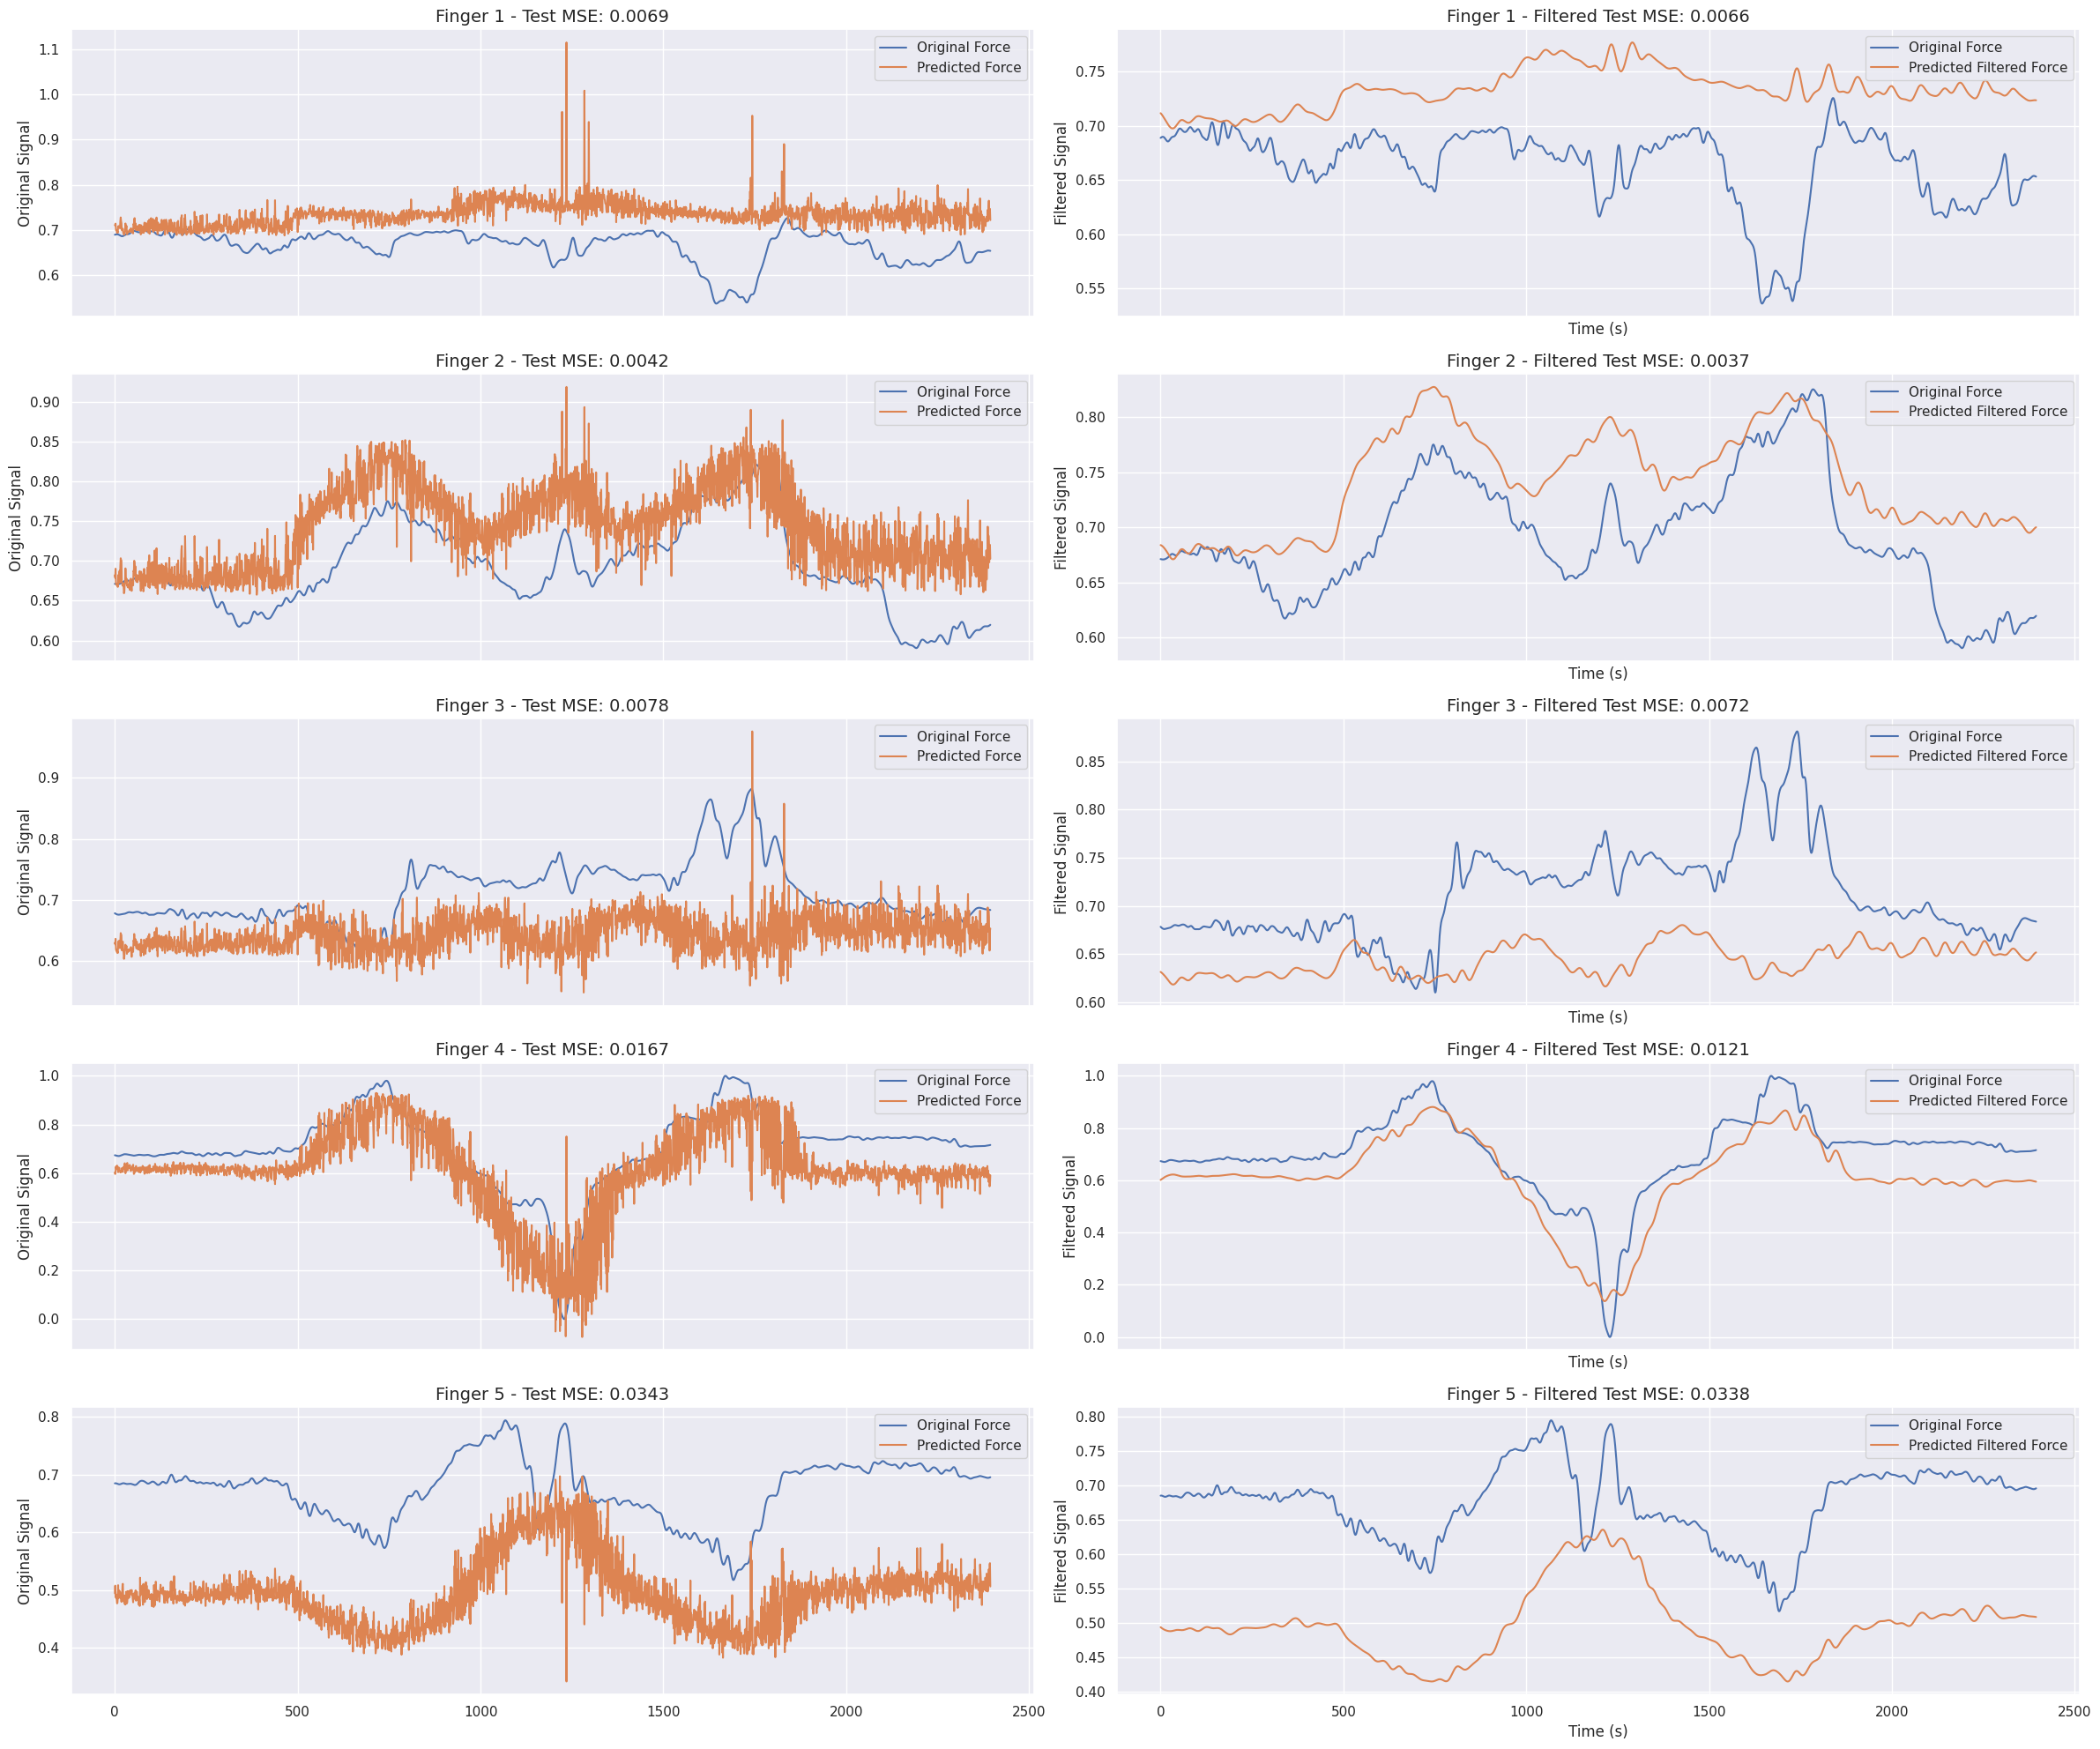

In [ ]:
predicted_test = np.array(y_pred_f)
outputs = np.array(force_signal_val)
y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

plt.tight_layout()
plt.show()

In [ ]:
for i in range(5):
    print(f'Finger {i+1} - r^2: {r2(y[:,i], outputs[:,i])}')

Finger 1 - r^2: -19.03023505682787
Finger 2 - r^2: -0.7674506750942629
Finger 3 - r^2: -26.961008211347735
Finger 4 - r^2: 0.547175941341735
Finger 5 - r^2: -11.104437083672854


# Outros dedos

## Load models

In [ ]:
estimator_f1 = estimator_f4
estimator_f2 = estimator_f4
estimator_f3 = estimator_f4
estimator_f4 = estimator_f4
estimator_f5 = estimator_f4

In [ ]:
# Cria um objeto `tf.train.Checkpoint` com o modelo
checkpoint1 = tf.train.Checkpoint(model=estimator_f1)

# Restaura os valores salvos no modelo a partir dos arquivos de checkpoint
checkpoint1.restore(
    "gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_1/"
)

In [ ]:
checkpoint2 = tf.train.Checkpoint(model=estimator_f2)

# Restaura os valores salvos no modelo a partir dos arquivos de checkpoint
checkpoint2.restore(
    "gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_2/"
)

In [ ]:
checkpoint3 = tf.train.Checkpoint(model=estimator_f3)

# Restaura os valores salvos no modelo a partir dos arquivos de checkpoint
checkpoint3.restore(
    "gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_3/"
)

In [ ]:
checkpoint4 = tf.train.Checkpoint(model=estimator_f4)

# Restaura os valores salvos no modelo a partir dos arquivos de checkpoint
checkpoint4.restore(
    "gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_4/"
)

In [ ]:
checkpoint5 = tf.train.Checkpoint(model=estimator_f5)

# Restaura os valores salvos no modelo a partir dos arquivos de checkpoint
checkpoint5.restore(
    "gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_5/"
)

### Extract the EMG from the dataloaders

In [ ]:
def data_extraction(dataset):
    emg_signal_windows, force_signal = [], []
    for emg, f in dataset:
        emg_signal_windows.append(emg)
        force_signal.append(f)
    emg_signal_windows = tf.constant(
        np.array(emg_signal_windows)
    )
    force_signal = tf.constant(
        np.array(force_signal)
    )
    return emg_signal_windows, force_signal

In [ ]:
emg_signal_windows_train_1, force_signal_train_1 = data_extraction(train_dataset_f1)
emg_signal_windows_train_2, force_signal_train_2 = data_extraction(train_dataset_f2)
emg_signal_windows_train_3, force_signal_train_3 = data_extraction(train_dataset_f3)
emg_signal_windows_train_4, force_signal_train_4 = data_extraction(train_dataset_f4)
emg_signal_windows_train_5, force_signal_train_5 = data_extraction(train_dataset_f5)

In [ ]:
emg_signal_windows_val_1, force_signal_val_1 = data_extraction(val_dataset_f1)
emg_signal_windows_val_2, force_signal_val_2 = data_extraction(val_dataset_f2)
emg_signal_windows_val_3, force_signal_val_3 = data_extraction(val_dataset_f3)
emg_signal_windows_val_4, force_signal_val_4 = data_extraction(val_dataset_f4)
emg_signal_windows_val_5, force_signal_val_5 = data_extraction(val_dataset_f5)

In [ ]:
emg_signal_windows_test_1, force_signal_test_1 = data_extraction(test_dataset_f1)
emg_signal_windows_test_2, force_signal_test_2 = data_extraction(test_dataset_f2)
emg_signal_windows_test_3, force_signal_test_3 = data_extraction(test_dataset_f3)
emg_signal_windows_test_4, force_signal_test_4 = data_extraction(test_dataset_f4)
emg_signal_windows_test_5, force_signal_test_5 = data_extraction(test_dataset_f5)

### Feature Extraction

In [ ]:
features_extractor_1 = estimator_f1
features_extractor_2 = estimator_f2
features_extractor_3 = estimator_f3
features_extractor_4 = estimator_f4
features_extractor_5 = estimator_f5

In [ ]:
features_train_1 = estimator_f1.predict(emg_signal_windows_train_1)
features_train_2 = estimator_f2.predict(emg_signal_windows_train_2)
features_train_3 = estimator_f3.predict(emg_signal_windows_train_3)
features_train_4 = estimator_f4.predict(emg_signal_windows_train_4)
features_train_5 = estimator_f5.predict(emg_signal_windows_train_5)

150/150 [==============================] - 35s 234ms/step


In [ ]:
features_train_1.shape

(4790, 16)

In [ ]:
eatures_val_1 = estimator_f1.predict(emg_signal_windows_val_1)
features_val_2 =estimator_f2.predict(emg_signal_windows_val_2)
features_val_3 =estimator_f3.predict(emg_signal_windows_val_3)
features_val_4 =estimator_f4.predict(emg_signal_windows_val_4)
features_val_5 =estimator_f5.predict(emg_signal_windows_val_5)

75/75 [==============================] - 17s 234ms/step


In [ ]:
features_test_1 = estimator_f1.predict(emg_signal_windows_test_1)
features_test_2 = estimator_f2.predict(emg_signal_windows_test_2)
features_test_3 = estimator_f3.predict(emg_signal_windows_test_3)
features_test_4 = estimator_f4.predict(emg_signal_windows_test_4)
features_test_5 = estimator_f5.predict(emg_signal_windows_test_5)

75/75 [==============================] - 17s 235ms/step


## Test

### Finger 1

In [ ]:
os_elm_1 = OS_ELM(input_size=16, output_size=1, hidden_layer_size=128)
os_elm_1.fit(features_train_1, force_signal_train_1)
y_pred_f = os_elm_1.predict(features_test_1)

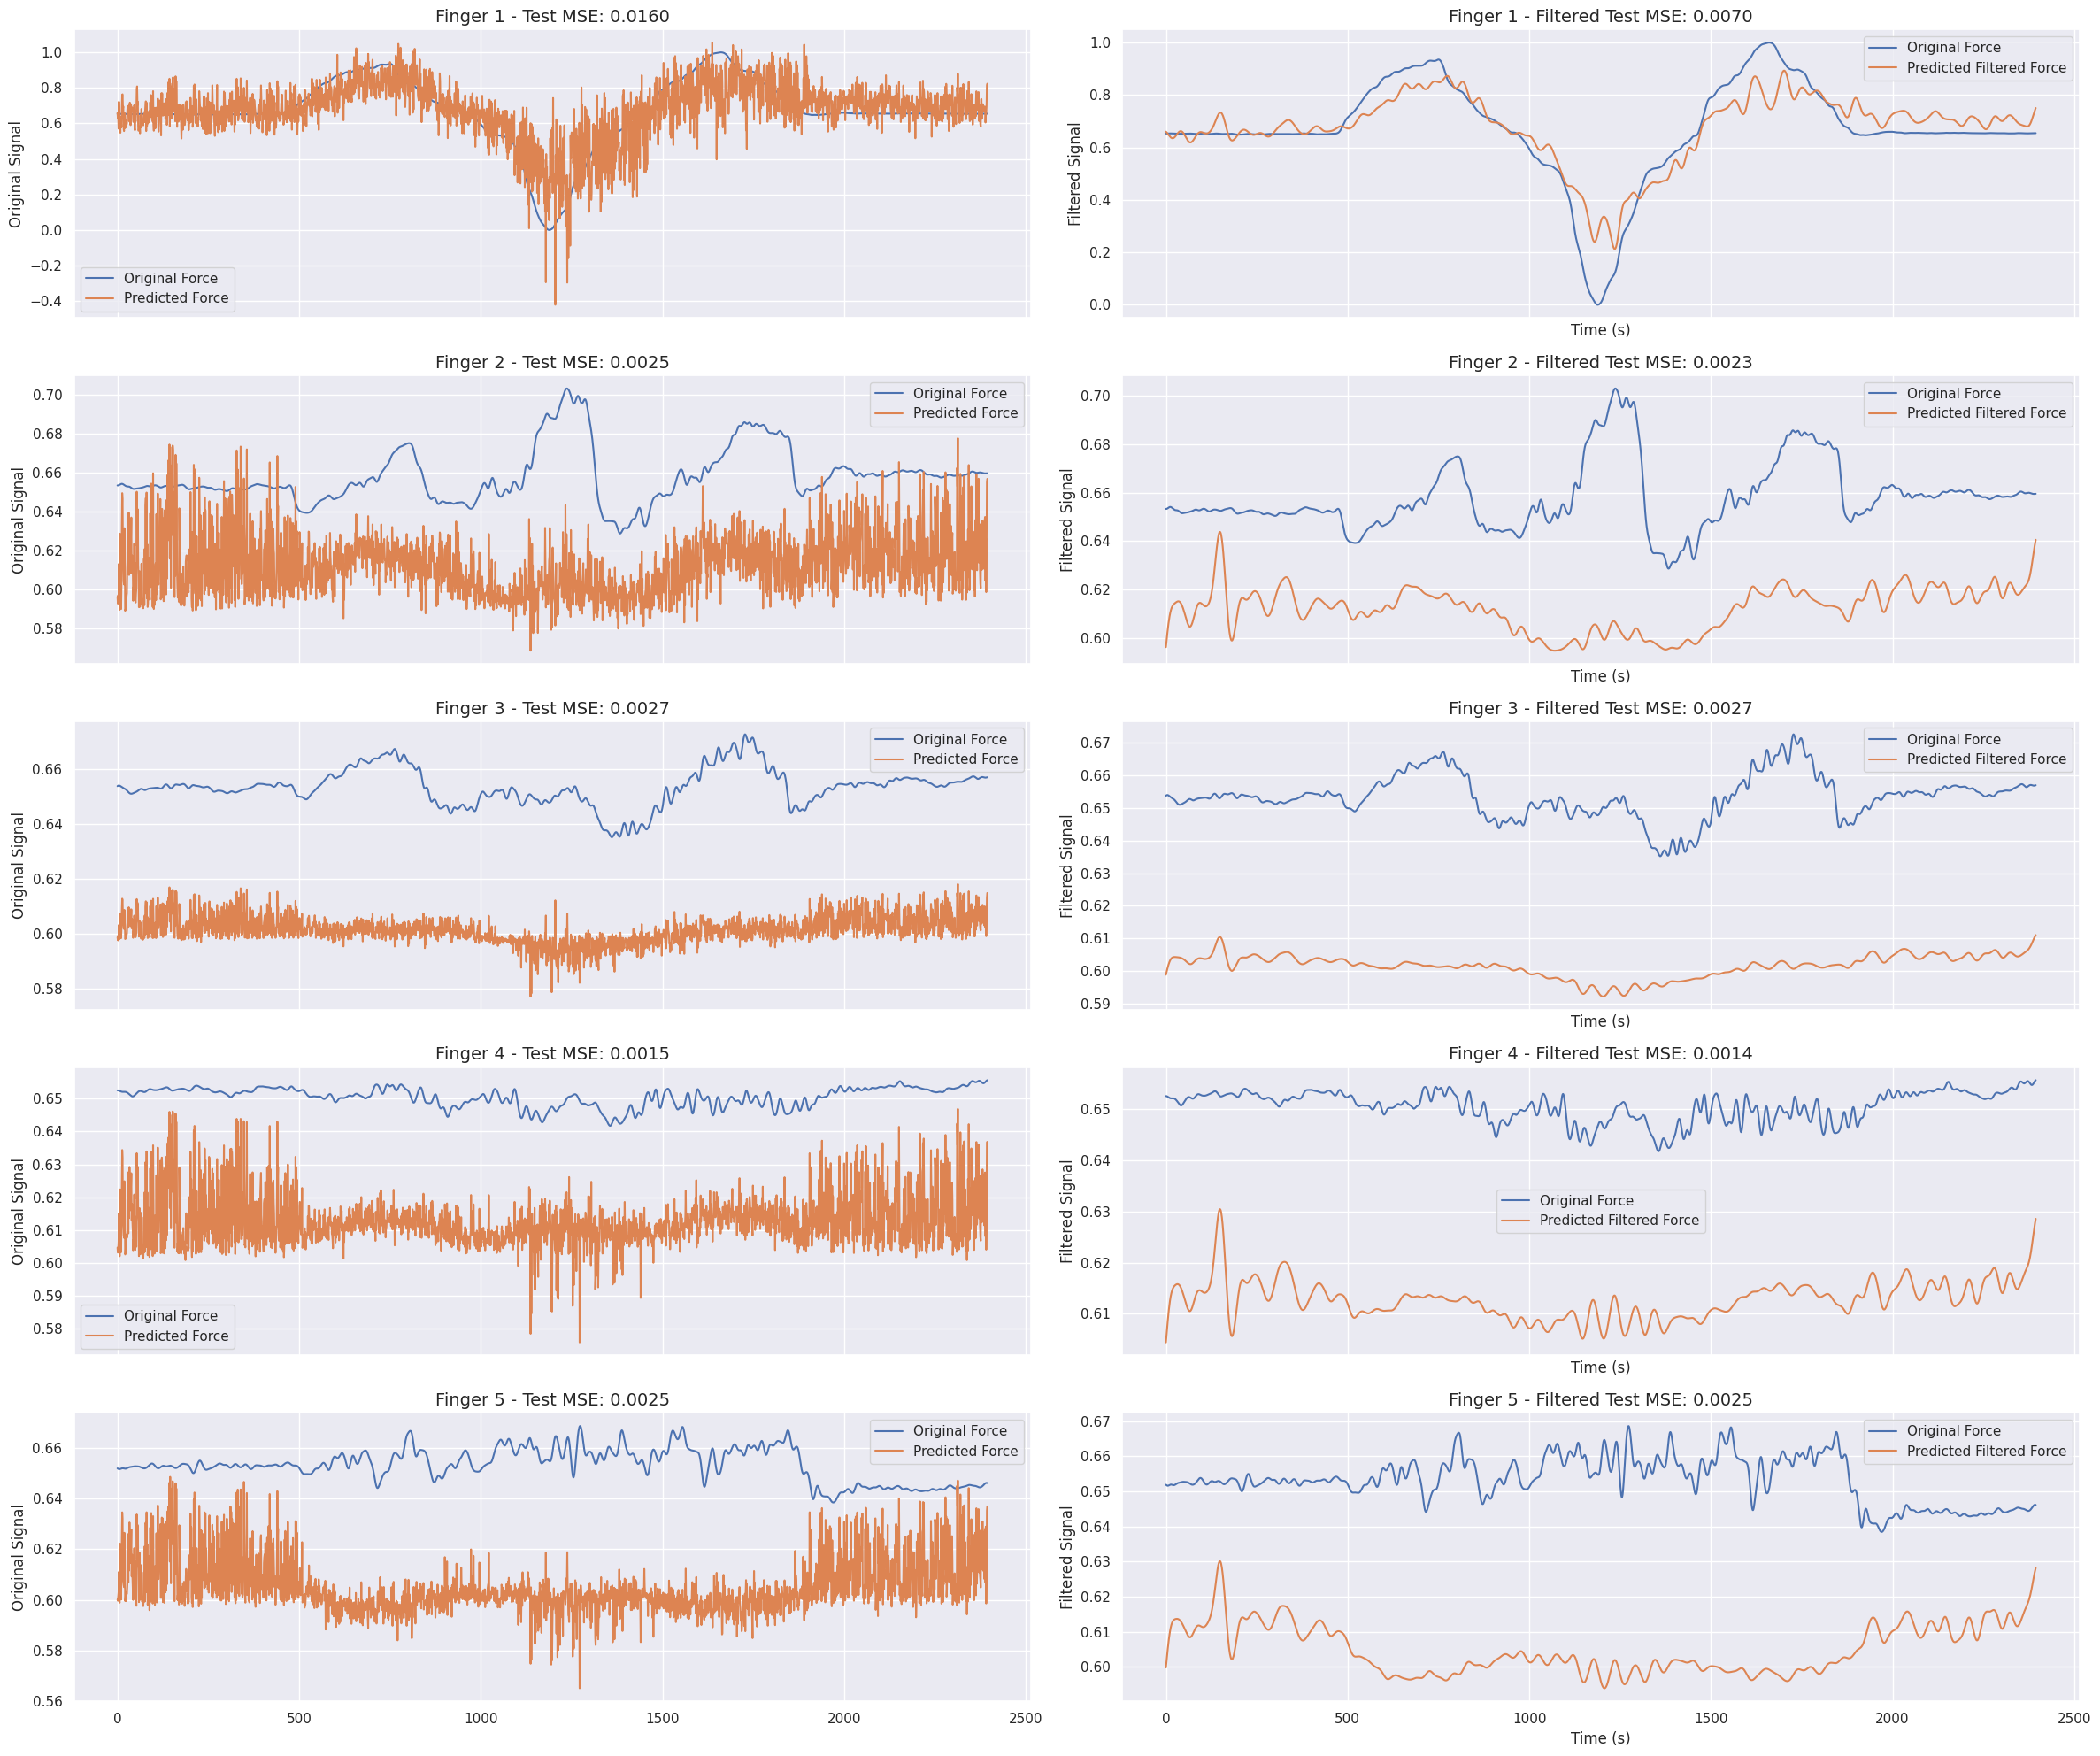

In [ ]:
from scipy.signal import butter, filtfilt, iirnotch

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

predicted_test = np.array(y_pred_f)
outputs = np.array(force_signal_test_1)
y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

plt.tight_layout()
plt.show()

In [ ]:
for i in range(5):
    print(f'Finger {i+1} - r^2: {r2(y[:,i], outputs[:,i])}')

Finger 1 - r^2: 0.5949193987001334
Finger 2 - r^2: -28.627779774648108
Finger 3 - r^2: -228.88171799770566
Finger 4 - r^2: -103.01054025917949
Finger 5 - r^2: -49.3532419064405


### Finger 2

In [ ]:
os_elm_2 = OS_ELM(input_size=16, output_size=5, hidden_layer_size=128)
os_elm_2.fit(features_train_2, force_signal_train_2)
y_pred_f = os_elm_2.predict(features_test_2)

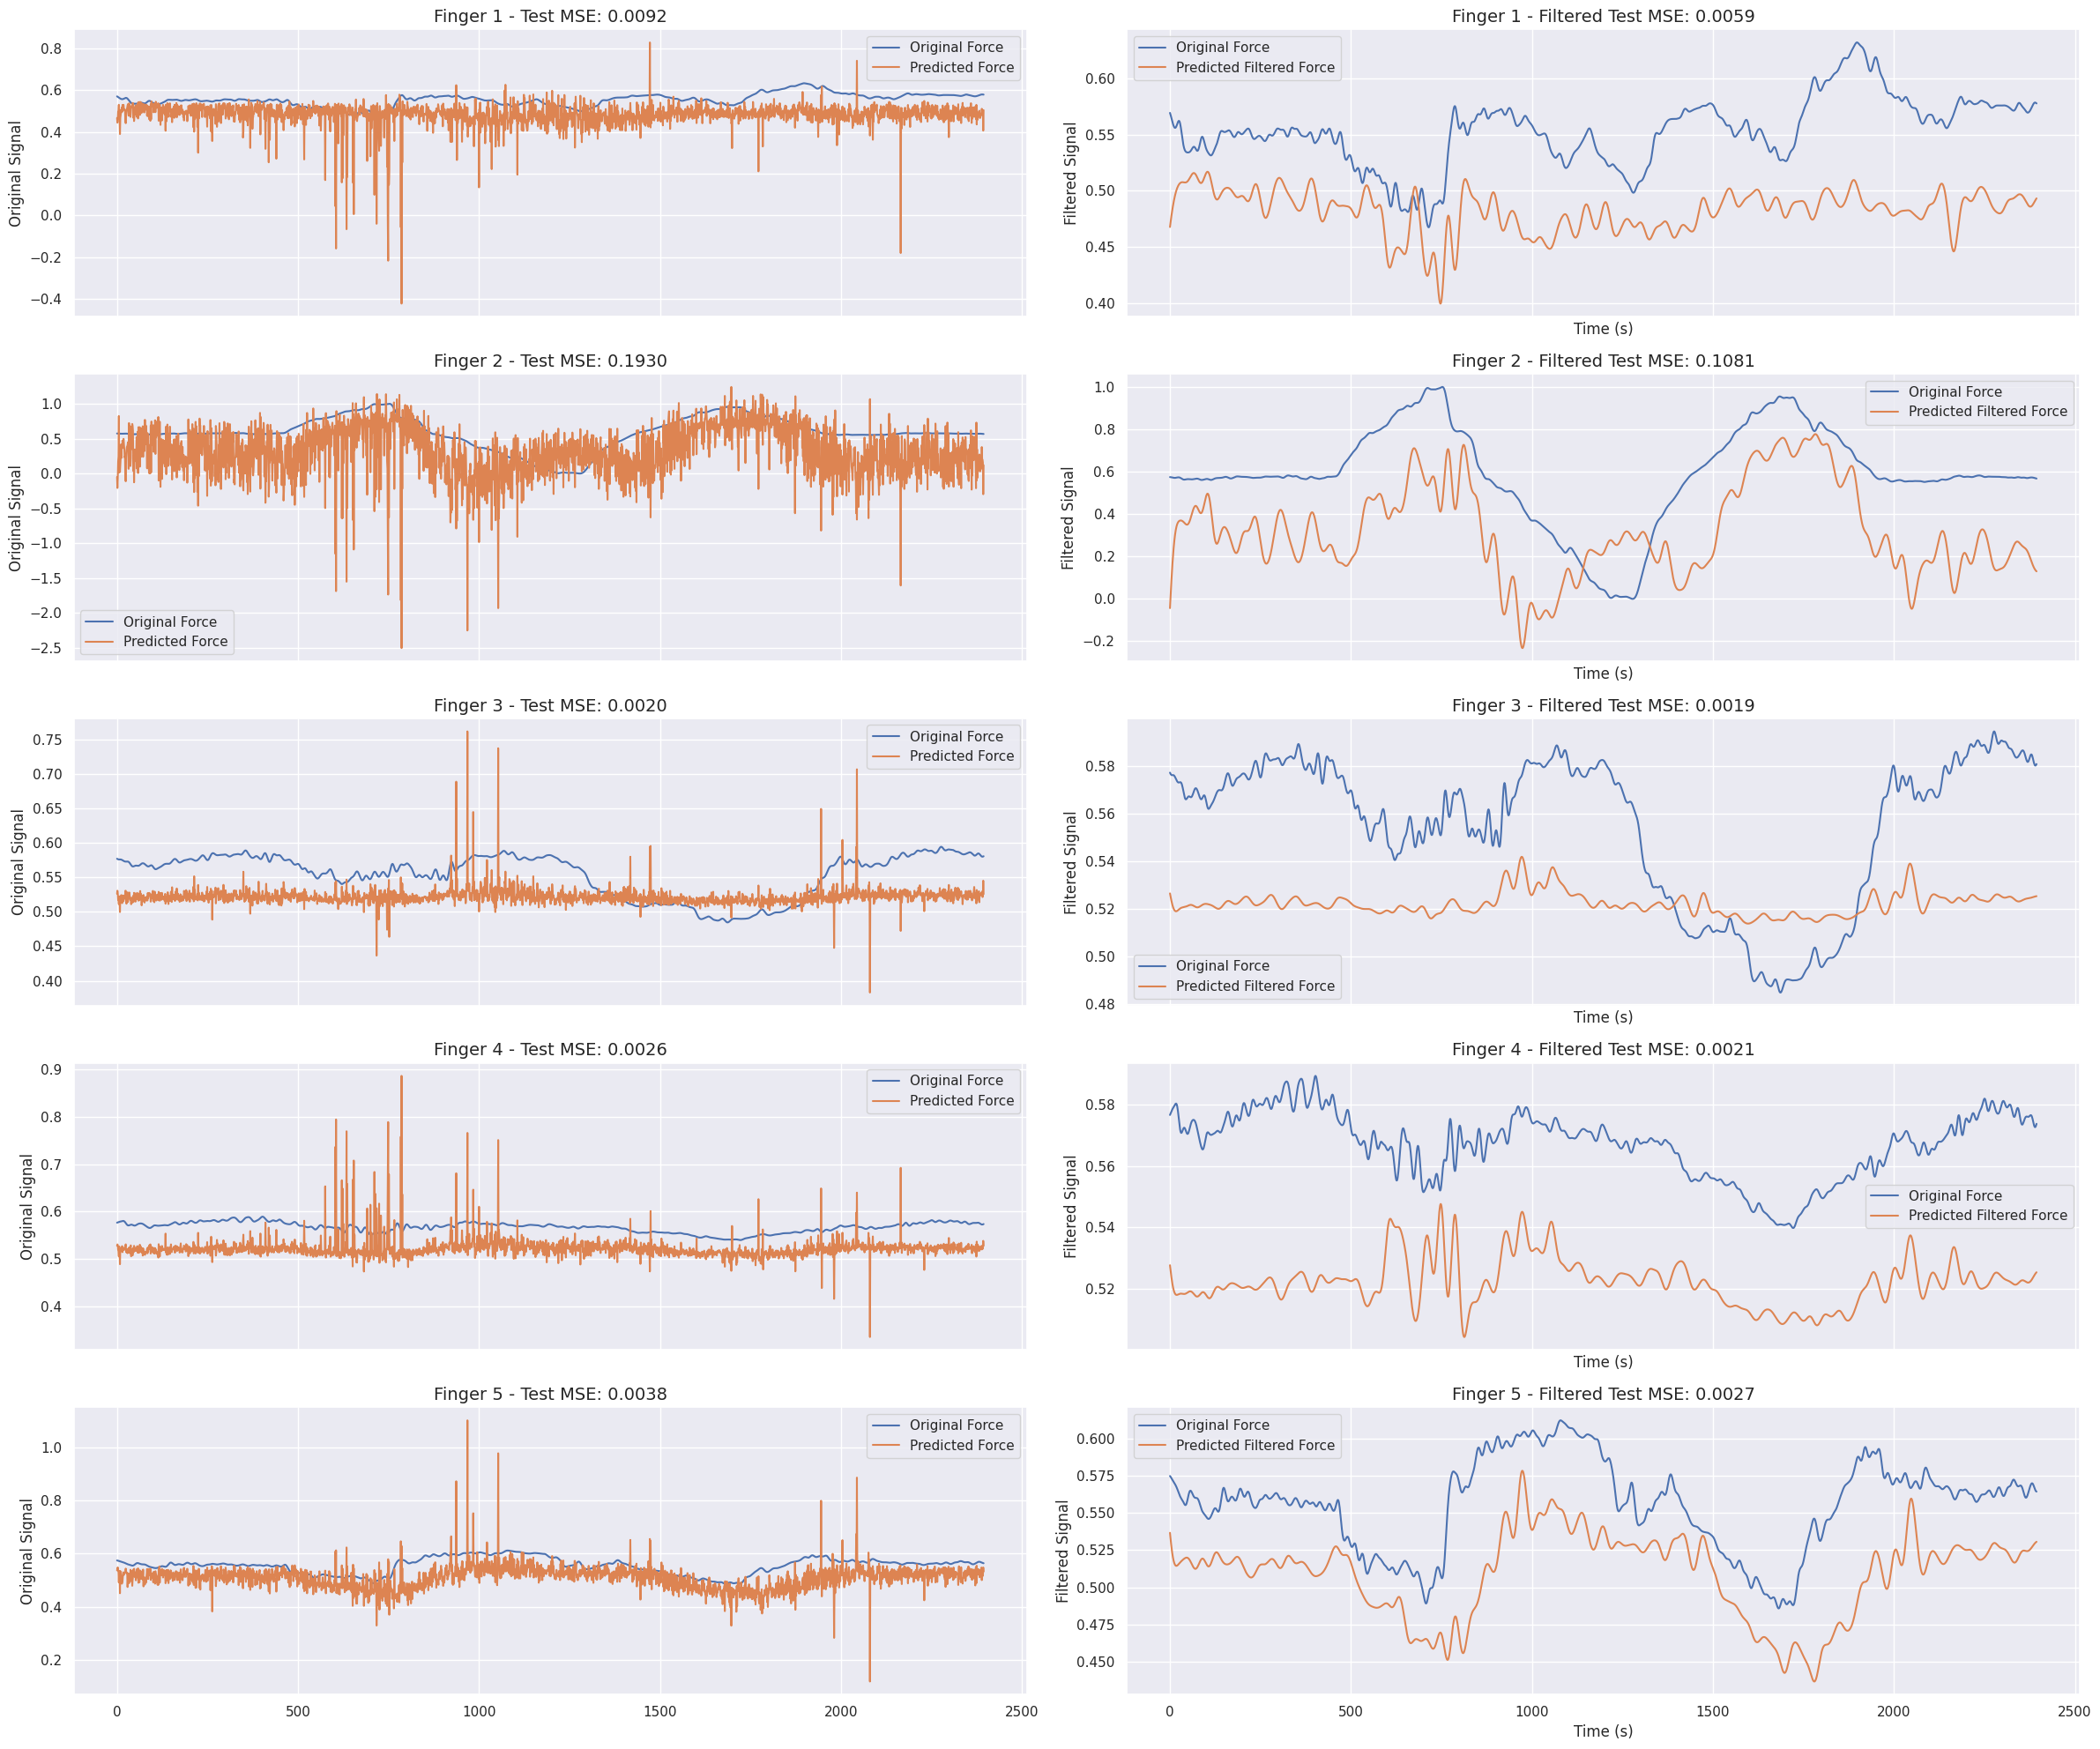

In [ ]:
predicted_test = np.array(y_pred_f)
outputs = np.array(force_signal_test_2)
y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

plt.tight_layout()
plt.show()

In [ ]:
for i in range(5):
    print(f'Finger {i+1} - r^2: {r2(y[:,i], outputs[:,i])}')

Finger 1 - r^2: -15.903230321195142
Finger 2 - r^2: -1.316839926511506
Finger 3 - r^2: -84.66504758815448
Finger 4 - r^2: -34.76421120886962
Finger 5 - r^2: -2.3835742796766346


### Finger 3

In [ ]:
os_elm_3 = OS_ELM(input_size=16, output_size=5, hidden_layer_size=128)
os_elm_3.fit(features_train_3, force_signal_train_3)
y_pred_f = os_elm_3.predict(features_test_3)

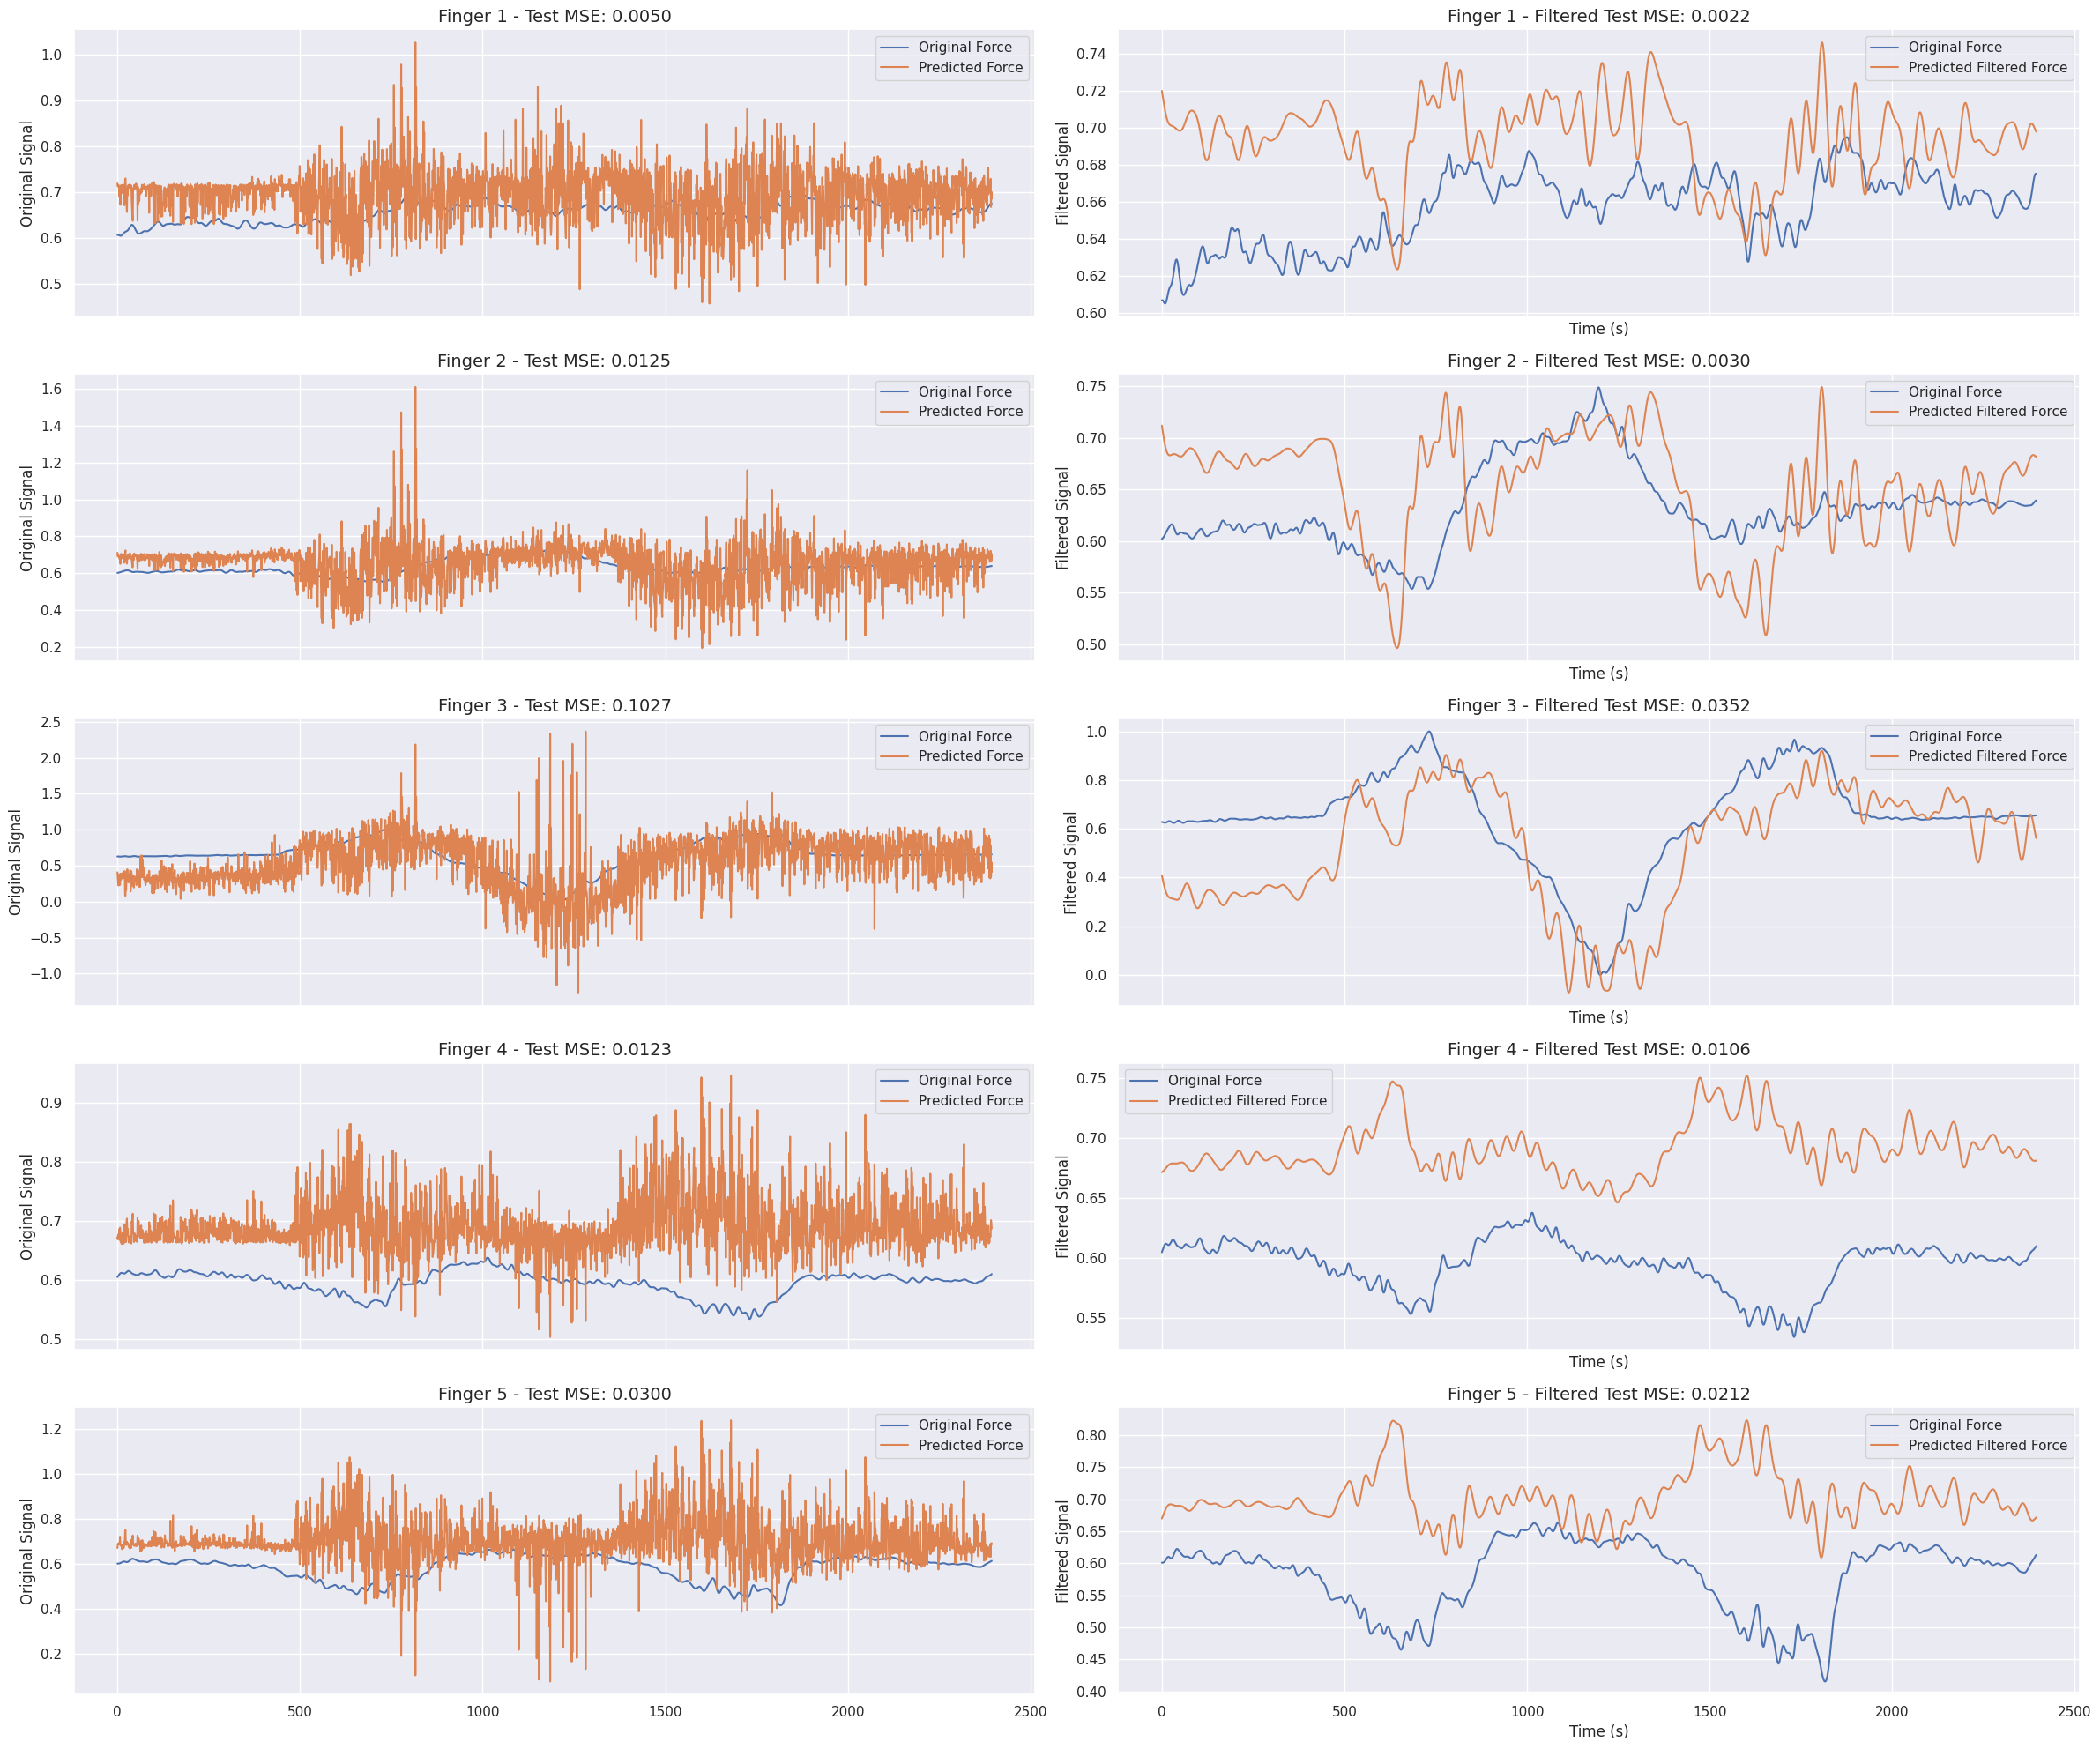

In [ ]:
predicted_test = np.array(y_pred_f)
outputs = np.array(force_signal_val_3)
y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

plt.tight_layout()
plt.show()

In [ ]:
for i in range(5):
    print(f'Finger {i+1} - r^2: {r2(y[:,i], outputs[:,i])}')

Finger 1 - r^2: -3.7610411944145286
Finger 2 - r^2: -0.07804789860971417
Finger 3 - r^2: 0.4244974814055148
Finger 4 - r^2: -22.25507394093571
Finger 5 - r^2: -12.067247972307944


### Finger 4

In [ ]:
os_elm_4 = OS_ELM(input_size=16, output_size=5, hidden_layer_size=128)
os_elm_4.fit(features_train_4, force_signal_train_4)
y_pred_f = os_elm_4.predict(features_test_4)

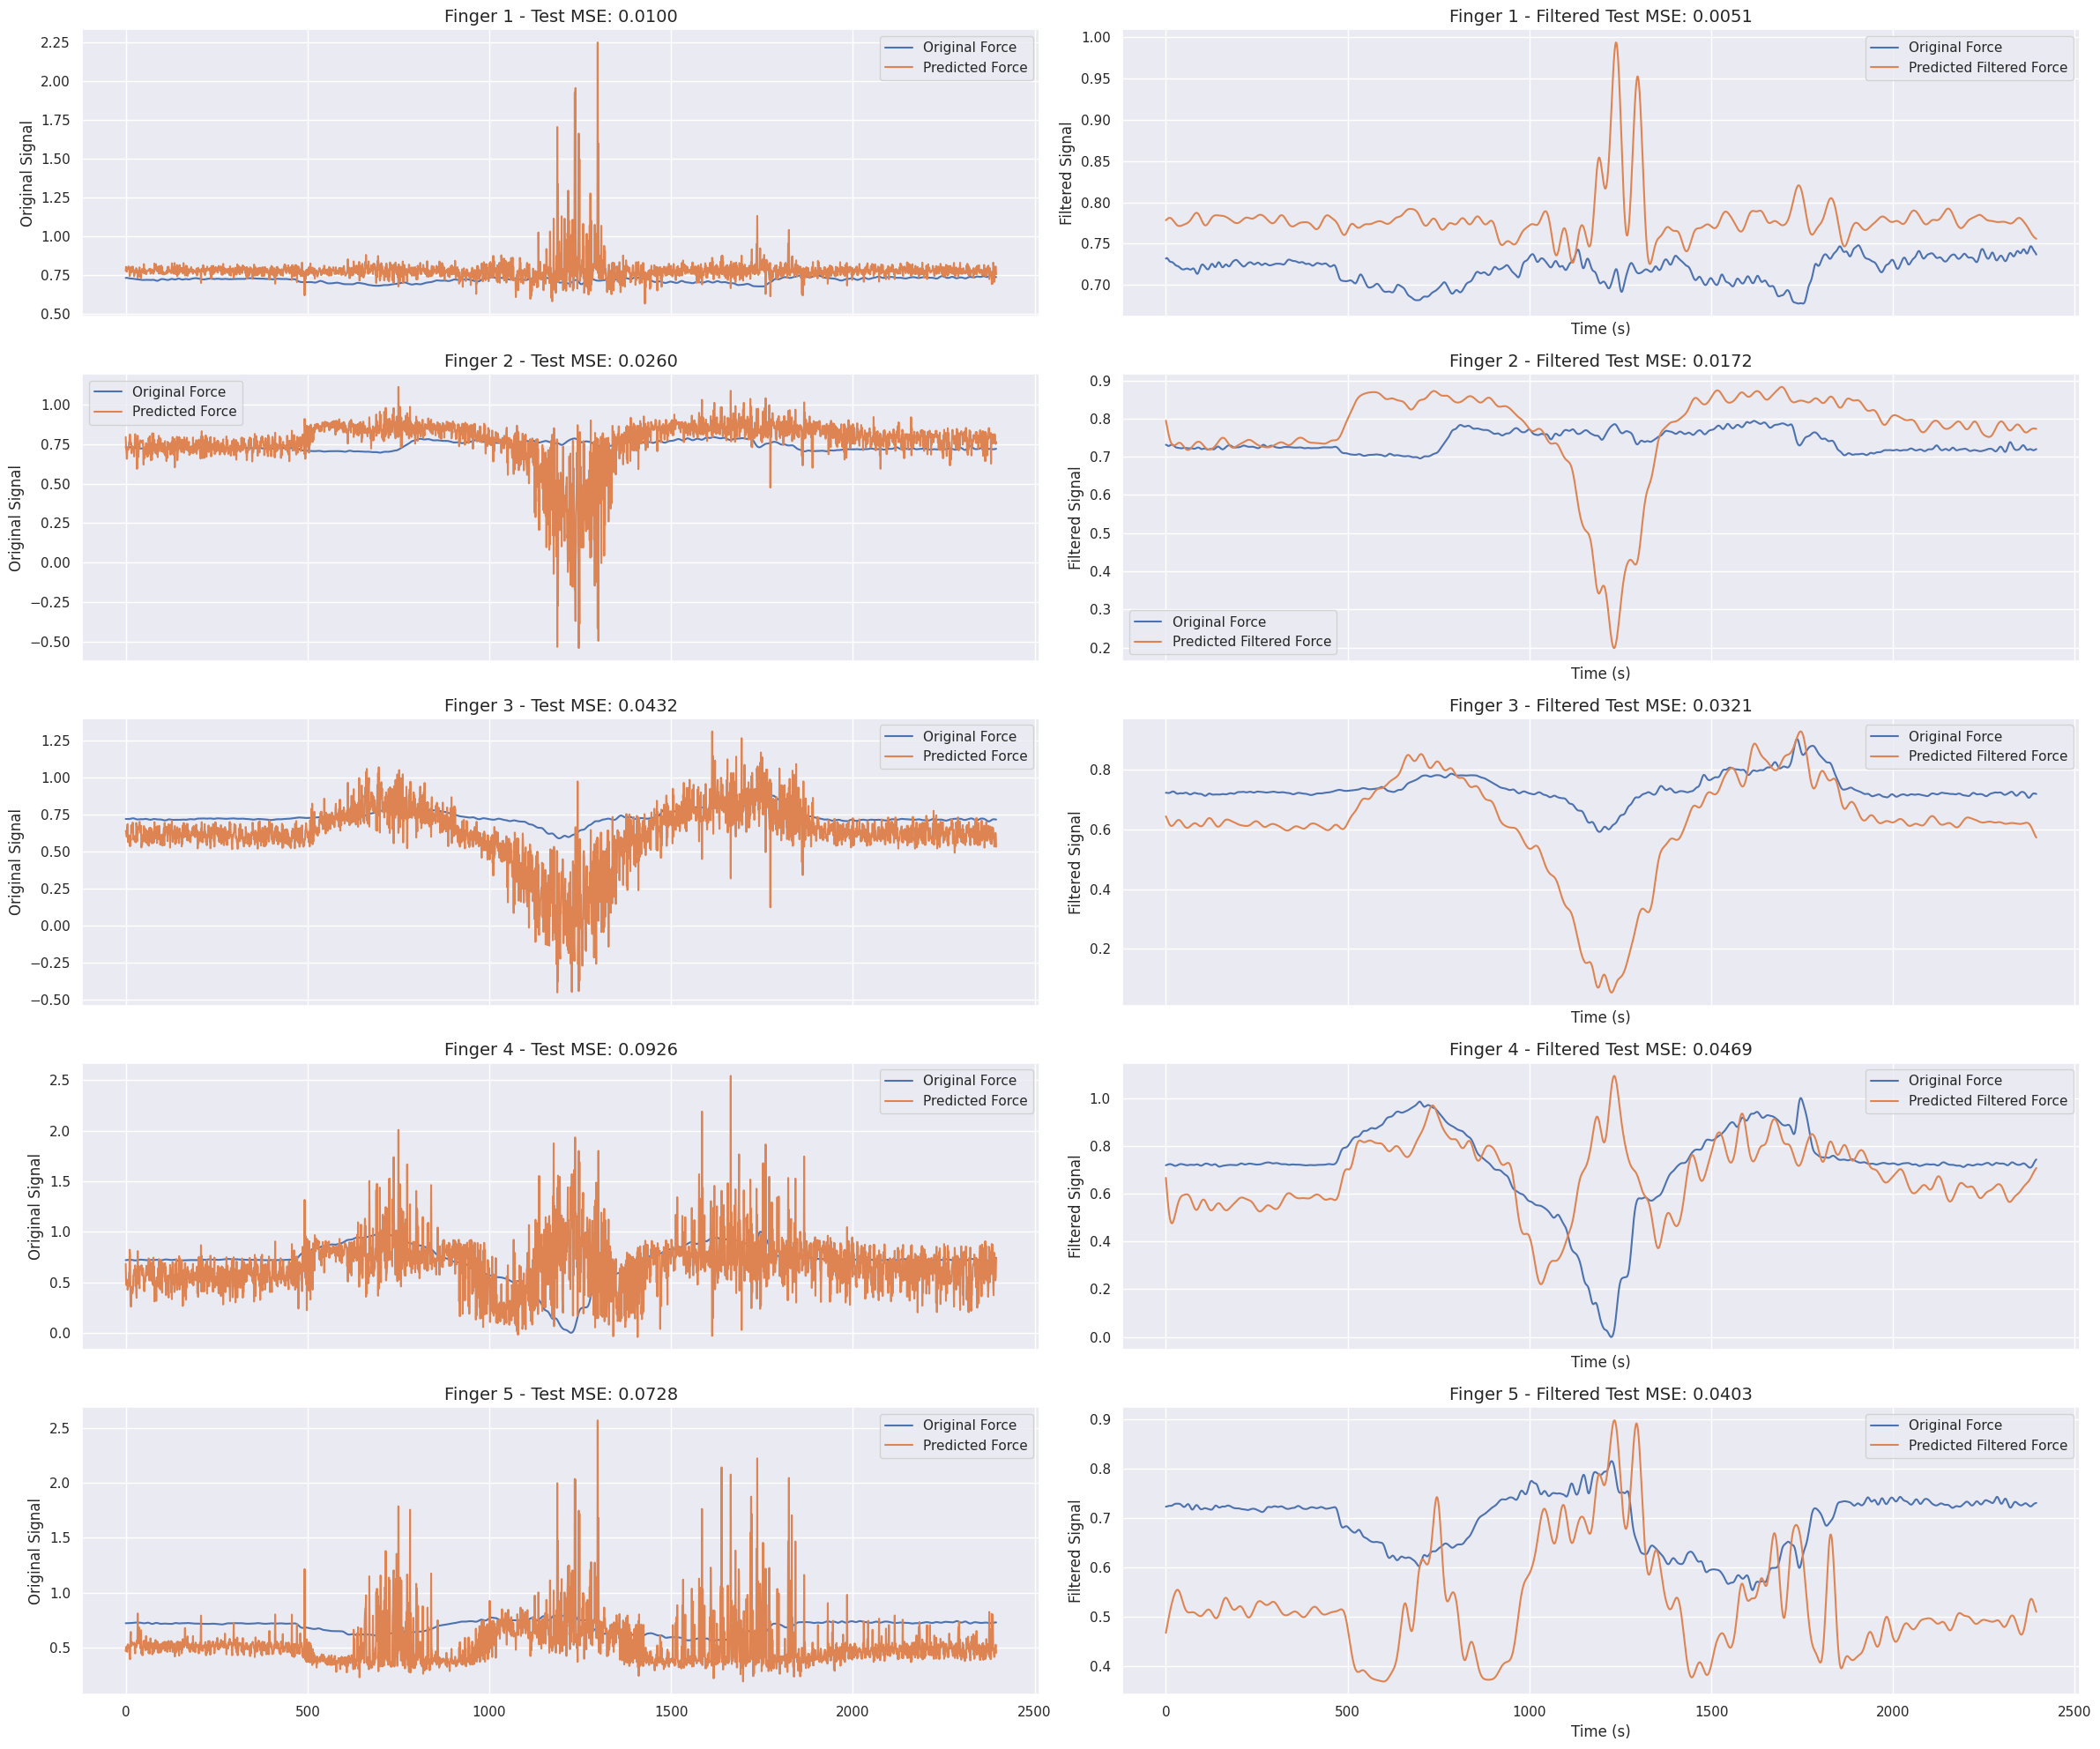

In [ ]:
predicted_test = np.array(y_pred_f)
outputs = np.array(force_signal_test_4)
y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

plt.tight_layout()
plt.show()

In [ ]:
for i in range(5):
    print(f'Finger {i+1} - r^2: {r2(y[:,i], outputs[:,i])}')

Finger 1 - r^2: -4.783807269536886
Finger 2 - r^2: -0.15021347679410013
Finger 3 - r^2: -0.05274593091602764
Finger 4 - r^2: -1.1237538457889014
Finger 5 - r^2: -2.5832531231225304


### Finger 5

In [ ]:
os_elm_5 = OS_ELM(input_size=16, output_size=1, hidden_layer_size=128)
os_elm_5.fit(features_train_5, force_signal_train_5)
y_pred_f = os_elm_5.predict(features_test_5)

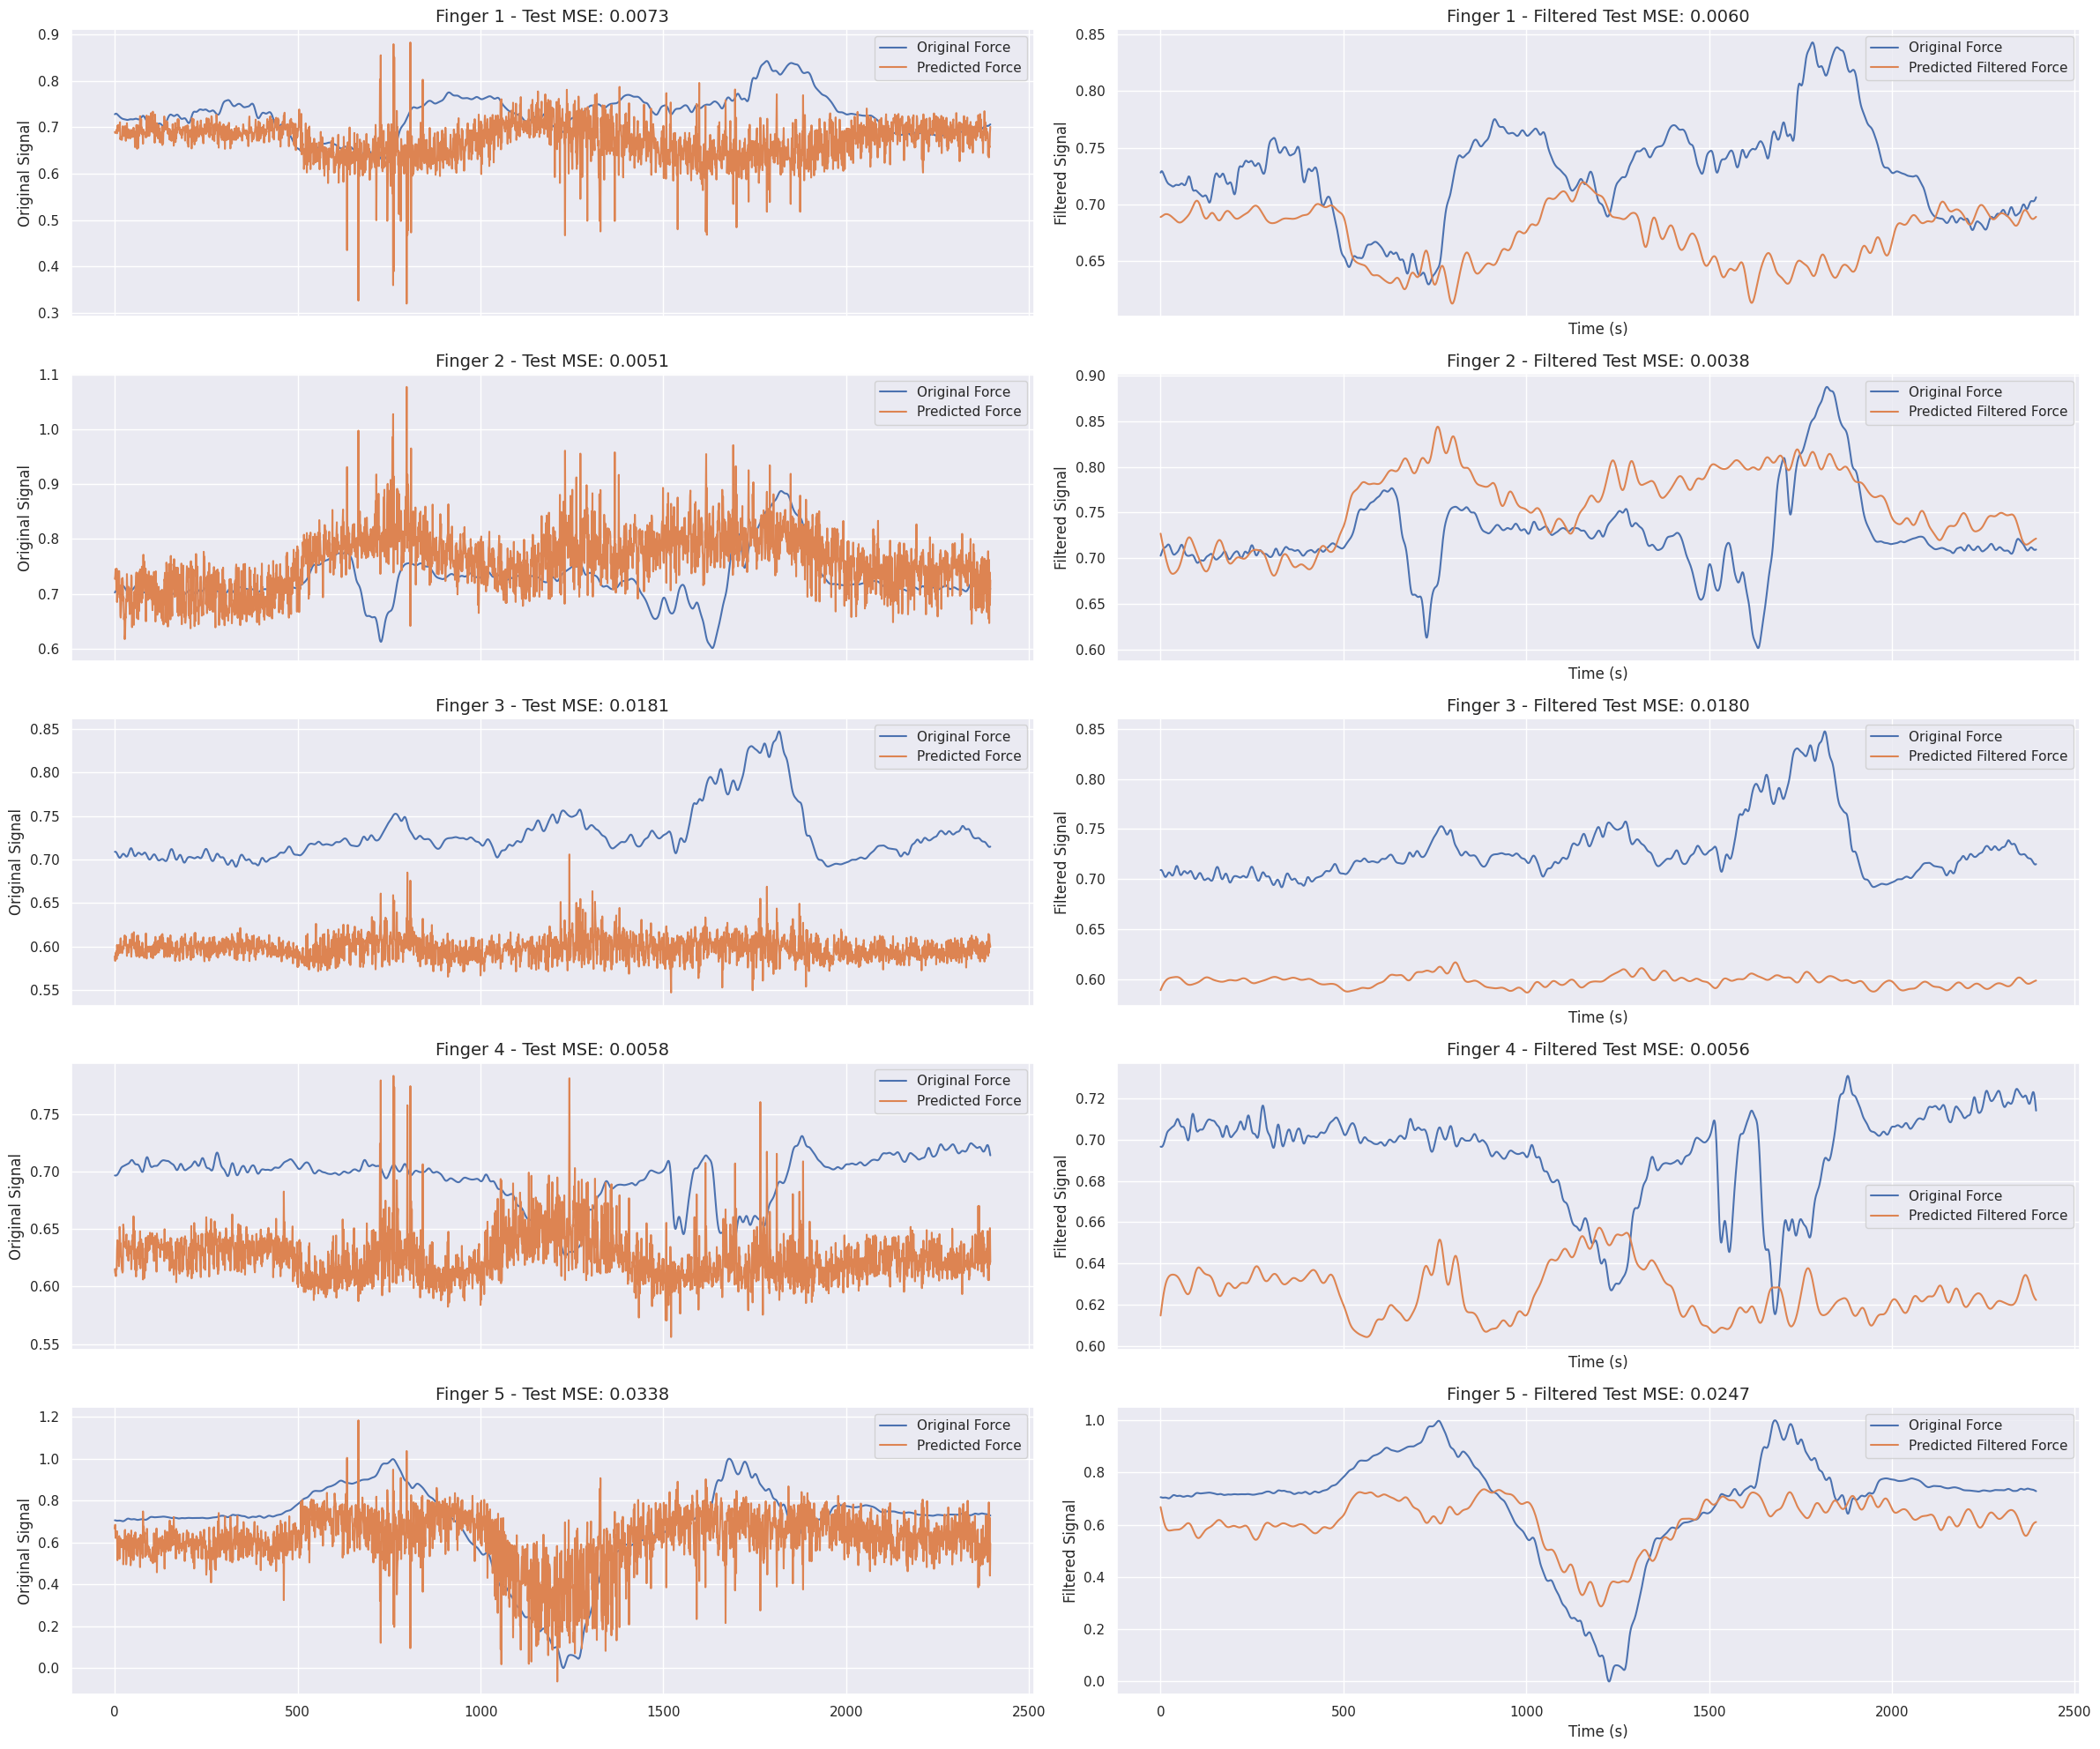

In [ ]:
predicted_test = np.array(y_pred_f)
outputs = np.array(force_signal_test_5)
y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

fig, ax = plt.subplots(5, 2, sharex=True, figsize=(24, 20))

for channel in range(5):
    # Calculate MSE for the original and filtered signals of the current channel
    mse_original = calc_mse(predicted_test[:, channel], outputs[:, channel])
    mse_filtered = calc_mse(y[:, channel], outputs[:, channel])

    # Plot the original signal and its prediction
    ax[channel, 0].set_title(f"Finger {channel + 1} - Test MSE: {mse_original:.4f}", fontsize=14)
    ax[channel, 0].plot(outputs[:, channel], label='Original Force')
    ax[channel, 0].plot(predicted_test[:, channel], label='Predicted Force')
    ax[channel, 0].set_ylabel('Original Signal')
    ax[channel, 0].legend()

    # Plot the filtered signal and its prediction
    ax[channel, 1].set_title(f"Finger {channel + 1} - Filtered Test MSE: {mse_filtered:.4f}", fontsize=14)
    ax[channel, 1].plot(outputs[:, channel], label='Original Force')
    ax[channel, 1].plot(y[:, channel], label='Predicted Filtered Force')
    ax[channel, 1].set_ylabel('Filtered Signal')
    ax[channel, 1].set_xlabel('Time (s)')
    ax[channel, 1].legend()

plt.tight_layout()
plt.show()

In [ ]:
for i in range(5):
    print(f'Finger {i+1} - r^2: {r2(y[:,i], outputs[:,i])}')

Finger 1 - r^2: -8.633402180709803
Finger 2 - r^2: -1.3865803904022265
Finger 3 - r^2: -597.5588337594329
Finger 4 - r^2: -36.851110464266625
Finger 5 - r^2: -1.822356286147628


# Test for OSELM

In [ ]:
# import tensorflow as tf
# from tensorflow.keras.layers import Layer
# from tensorflow.keras.models import Model
# from tensorflow.keras.optimizers import Adam

In [ ]:
# import numpy as np
#
#
# class OS_ELM:
#     def __init__(self, input_size, output_size, hidden_layer_size, random_state=None):
#         self.input_size = input_size
#         self.output_size = output_size
#         self.hidden_layer_size = hidden_layer_size
#         self.input_weights = np.random.uniform(-1, 1, size=[input_size, hidden_layer_size], random_state=random_state)
#         self.bias = np.random.uniform(-1, 1, size=[hidden_layer_size], random_state=random_state)
#         self.output_weights = np.random.uniform(-1, 1, size=[hidden_layer_size + 1, output_size], random_state=random_state)
#         self.random_state = random_state
#         self.H = None
#         self.beta = None
#
#     def relu(self, x):
#         return np.maximum(0, x)
#
#     def fit(self, X, y, regularization=0, batch_size=None):
#         if self.random_state is not None:
#             np.random.seed(self.random_state)
#
#         if batch_size is None:
#             H = self.relu(np.dot(X, self.input_weights) + self.bias)
#             H = np.hstack([H, np.ones((H.shape[0], 1))])  # add bias term
#             self.beta = np.dot(np.linalg.pinv(H.T.dot(H) + regularization * np.eye(H.shape[1])), H.T.dot(y))
#         else:
#             n_samples = X.shape[0]
#             n_batches = int(np.ceil(n_samples / batch_size))
#             H_batches = []
#             y_batches = []
#             for i in range(n_batches):
#                 start = i * batch_size
#                 end = min((i + 1) * batch_size, n_samples)
#                 H_batch = self.relu(np.dot(X[start:end], self.input_weights) + self.bias)
#                 H_batch = np.hstack([H_batch, np.ones((H_batch.shape[0], 1))])  # add bias term
#                 H_batches.append(H_batch)
#                 y_batches.append(y[start:end])
#             H = np.vstack(H_batches)
#             y = np.vstack(y_batches)
#             self.beta = np.dot(np.linalg.pinv(H.T.dot(H) + regularization * np.eye(H.shape[1])), H.T.dot(y))
#
#         self.H = H
#
#     def predict(self, X):
#         H = self.relu(np.dot(X, self.input_weights) + self.bias)
#         H = np.hstack([H, np.ones((H.shape[0], 1))])  # add bias term
#         y_pred = np.dot(H, self.beta)
#         return y_pred

In [ ]:
# import tensorflow as tf
# from tensorflow.keras.layers import Layer
#
#
# class OSELM(tf.keras.layers.Layer):
#     def __init__(self, input_size, output_size, hidden_layer_size, regularization=0, random_state=None, **kwargs):
#         super(OSELM, self).__init__(**kwargs)
#         self.input_size = input_size
#         self.output_size = output_size
#         self.hidden_layer_size = hidden_layer_size
#         self.regularization = regularization
#         self.random_state = random_state
#         self.input_weights = None
#         self.bias = None
#         self.output_weights = None
#         self.H = None
#         self.beta = None
#
#         # Define the kernel attribute
#         self.kernel = tf.keras.layers.Dense(hidden_layer_size + 1, use_bias=False)
#
#     def build(self, input_shape):
#         input_size = input_shape[-1]
#         self.input_weights = self.add_weight(shape=(input_size, self.hidden_layer_size),
#                                              initializer='uniform',
#                                              trainable=True)
#         self.bias = self.add_weight(shape=(self.hidden_layer_size,),
#                                     initializer='uniform',
#                                     trainable=True)
#         self.output_weights = self.add_weight(shape=(self.hidden_layer_size + 1, self.output_size),
#                                               initializer='uniform',
#                                               trainable=True)
#         super(OSELM, self).build(input_shape)
#
#     def call(self, inputs):
#         if self.input_weights is None or self.bias is None or self.output_weights is None:
#             raise RuntimeError("OS-ELM layer has not been built.")
#
#         H = self.relu(tf.cast(tf.matmul(inputs, self.input_weights) + self.bias, tf.float32))
#         H = tf.concat([H, tf.ones((tf.shape(H)[0], 1))], axis=-1)  # add bias term
#         output = tf.matmul(H, self.output_weights)
#         return output
#
#     def call(self, inputs, outputs_1=0, flag=False):
#         if self.input_weights is None or self.bias is None or self.output_weights is None:
#             raise RuntimeError("TFOS_ELM layer has not been built.")
#
#         H = self.relu(tf.cast(tf.matmul(inputs, self.input_weights) + self.bias, tf.float32))
#         H = tf.concat([H, tf.ones((tf.shape(H)[0], 1))], axis=-1)  # add bias term
#         output = tf.matmul(H, self.output_weights)
#
#         if flag:
#             # Set the loss function
#             loss = tf.keras.losses.MeanSquaredError()
#
#             # Compute the loss
#             loss_value = loss(output, outputs_1)
#
#         return output, loss_value
#
#     def relu(self, x):
#         return tf.maximum(0.0, tf.cast(x, tf.float32))

In [ ]:
# class OS_ELM:
#     def __init__(self, input_size, output_size, hidden_layer_size, random_state=None):
#         self.input_size = input_size
#         self.output_size = output_size
#         self.hidden_layer_size = hidden_layer_size
#         self.input_weights = tf.Variable(tf.random.uniform(shape=[input_size, hidden_layer_size], minval=-1, maxval=1))
#         self.bias = tf.Variable(tf.random.uniform(shape=[hidden_layer_size], minval=-1, maxval=1))
#         self.output_weights = tf.Variable(tf.random.uniform(shape=[hidden_layer_size + 1, output_size], minval=-1, maxval=1))
#         self.random_state = random_state
#         self.H = None
#         self.beta = None
#
#     def relu(self, x):
#         return tf.maximum(0, x)
#
#     def fit(self, X, y, regularization=0, batch_size=None):
#         if self.random_state is not None:
#             tf.random.set_seed(self.random_state)
#
#         X = tf.convert_to_tensor(X, dtype=tf.float32)
#         y = tf.convert_to_tensor(y, dtype=tf.float32)
#
#         if batch_size is None:
#             H = self.relu(tf.matmul(X, self.input_weights) + self.bias)
#             H = tf.concat([H, tf.ones((tf.shape(H)[0], 1))], axis=-1)  # add bias term
#             self.beta = tf.linalg.pinv(tf.matmul(tf.transpose(H), H) + regularization * tf.eye(H.shape[1])) @ tf.matmul(tf.transpose(H), y)
#         else:
#             n_samples = X.shape[0]
#             n_batches = int(tf.math.ceil(n_samples / batch_size))
#             H_batches = []
#             y_batches = []
#             for i in range(n_batches):
#                 start = i * batch_size
#                 end = min((i + 1) * batch_size, n_samples)
#                 H_batch = self.relu(tf.matmul(X[start:end], self.input_weights) + self.bias)
#                 H_batch = tf.concat([H_batch, tf.ones((tf.shape(H_batch)[0], 1))], axis=-1)  # add bias term
#                 H_batches.append(H_batch)
#                 y_batches.append(y[start:end])
#             H = tf.concat(H_batches, axis=0)
#             y = tf.concat(y_batches, axis=0)
#             self.beta = tf.linalg.pinv(tf.matmul(tf.transpose(H), H) + regularization * tf.eye(H.shape[1])) @ tf.matmul(tf.transpose(H), y)
#
#         self.H = H
#
#     def predict(self, X):
#         X = tf.convert_to_tensor(X, dtype=tf.float32)
#         H = self.relu(tf.matmul(X, self.input_weights) + self.bias)
#         H = tf.concat([H, tf.ones((tf.shape(H)[0], 1))], axis=-1)  # add bias term
#         y_pred = tf.matmul(H, self.beta)
#         return y_pred

In [ ]:
# # Crie o seu modelo com a camada OSELM personalizada
# input_shape = (16,)  # Input shape do seu modelo
# num_hidden = 64  # Número de unidades ocultas na camada OSELM
#
#
# model = tf.keras.models.Sequential([
#     tf.keras.layers.Dense(64, activation='relu'),
#     tf.keras.layers.Dense(16, activation='relu'),
#     OSELM(input_size=16, output_size=1, hidden_layer_size=64),
#     tf.keras.layers.Dense(1)
# ])
#
# model.compile(optimizer='adam', loss='mse')
#
# # Treine o seu modelo normalmente usando a função train_on_batch para o OSELM
# batch_size = 32
# num_epochs = 10
#
# # Gere dados de treinamento aleatórios
# x_train = tf.random.normal((1000, 16))
# y_train = tf.random.normal((1000, 1))
#
# for epoch in range(num_epochs):
#     for batch in range(0, x_train.shape[0], batch_size):
#         x_batch = x_train[batch:batch+batch_size]
#         y_batch = y_train[batch:batch+batch_size]
#         model.train_on_batch(x_batch, y_batch)

In [ ]:
# from matplotlib import pyplot as plt
#
# predictions = model.predict(x_train)

In [ ]:
# # Plote a predição versus os dados de treinamento
# plt.plot(y_train)
# plt.plot(predictions)
# plt.xlabel('y_train')
# plt.ylabel('Predição')
# plt.title('Predição do treino vs y_train')
# plt.show()

In [ ]:
# output_size = 1
# hidden_layer_size = 128
# input_size = 16
# num_samples = 1000
#
# # Instantiate the TensorFlow model
# inputs = tf.keras.Input(shape=(input_size,))
# outputs = OSELM(input_size=16, output_size=1, hidden_layer_size=128)(inputs)
# tf_model = tf.keras.Model(inputs=inputs, outputs=outputs)
# tf_model.compile(optimizer='adam', loss='mse')
#
# # Instantiate the NumPy model
# np_model = OS_ELM(input_size, output_size, hidden_layer_size)
#
# # Generate some input data
# input_data = np.random.rand(num_samples, input_size)
#
# # Generate the output labels
# output_labels = np.random.rand(num_samples, output_size)
#
# # Train the TensorFlow model
# tf_model.build(input_shape=(16,))
# tf_model.fit(input_data, output_labels)
#
# # Train the NumPy model
# np_model.fit(input_data, output_labels)
#
# # Make predictions with the TensorFlow model
# tf_predictions = tf_model.predict(input_data)
#
# # Make predictions with the NumPy model
# np_predictions = np_model.predict(input_data)
#
# # Compare the predictions
# are_equal = np.allclose(tf_predictions, np_predictions, atol=1e-6)
# if are_equal:
#     print("The model outputs are equal.")
# else:
#     print("The model outputs are not equal.")

In [ ]:
# plt.plot(tf_predictions, label = 'tf')
# plt.plot(np_predictions, label = 'np')
# plt.xlabel('y_train')
# plt.ylabel('Predição')
# plt.title('tf vs np')
# plt.legend()
# plt.show()